In [87]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [88]:
import os
data_path = (
    '/content/international_matches (2).csv'
    if os.path.exists('/content/international_matches (2).csv')
    else '/mnt/data/international_matches (2).csv'
)
df = pd.read_csv(data_path)
df.head()


,date,home_team,away_team,home_team_continent,away_team_continent,home_team_fifa_rank,away_team_fifa_rank,home_team_total_fifa_points,away_team_total_fifa_points,home_team_score,...,shoot_out,home_team_result,home_team_goalkeeper_score,away_team_goalkeeper_score,home_team_mean_defense_score,home_team_mean_offense_score,home_team_mean_midfield_score,away_team_mean_defense_score,away_team_mean_offense_score,away_team_mean_midfield_score
0,1993-08-08,Bolivia,Uruguay,South America,South America,59,22,0,0,3,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1993-08-08,Brazil,Mexico,South America,North America,8,14,0,0,1,...,No,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1993-08-08,Ecuador,Venezuela,South America,South America,35,94,0,0,5,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1993-08-08,Guinea,Sierra Leone,Africa,Africa,65,86,0,0,1,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1993-08-08,Paraguay,Argentina,South America,South America,67,5,0,0,1,...,No,Lose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [89]:
df.shape

(23921, 25)

In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23921 entries, 0 to 23920
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   date                           23921 non-null  object 
 1   home_team                      23921 non-null  object 
 2   away_team                      23921 non-null  object 
 3   home_team_continent            23921 non-null  object 
 4   away_team_continent            23921 non-null  object 
 5   home_team_fifa_rank            23921 non-null  int64  
 6   away_team_fifa_rank            23921 non-null  int64  
 7   home_team_total_fifa_points    23921 non-null  int64  
 8   away_team_total_fifa_points    23921 non-null  int64  
 9   home_team_score                23921 non-null  int64  
 10  away_team_score                23921 non-null  int64  
 11  tournament                     23921 non-null  object 
 12  city                           23921 non-null 

In [91]:
df['date']=pd.to_datetime(df['date'])

In [92]:
fifa_rank=df[['date','home_team','away_team','home_team_fifa_rank','away_team_fifa_rank' ,'away_team_total_fifa_points','home_team_total_fifa_points']]
home=fifa_rank[['date','home_team','home_team_fifa_rank','home_team_total_fifa_points']].rename(columns={'home_team':'team','home_team_fifa_rank':'rank','home_team_total_fifa_points':'rank_points'})
away=fifa_rank[['date','away_team','away_team_fifa_rank','away_team_total_fifa_points']].rename(columns={'away_team':'team','away_team_fifa_rank':'rank','away_team_total_fifa_points':'rank_points'})
fifa_rank=pd.concat([home, away], ignore_index=True)
fifa_rank=fifa_rank.sort_values(['team','date'],ascending=[True,False])
fifa_rank['row_number']=fifa_rank.groupby('team').cumcount()+1
fifa_rank_top=fifa_rank[fifa_rank['row_number']==1].drop('row_number',axis=1).nsmallest(10,'rank')
fifa_rank_top

,date,team,rank,rank_points
47681,2022-06-06,Brazil,1,1832
47830,2022-06-14,Belgium,2,1827
23885,2022-06-13,France,3,1789
23741,2022-06-05,Argentina,4,1765
23906,2022-06-14,England,5,1761
47828,2022-06-14,Italy,6,1723
23866,2022-06-12,Spain,7,1709
47788,2022-06-12,Portugal,8,1674
47824,2022-06-14,Mexico,9,1658
23908,2022-06-14,Netherlands,10,1658


In [93]:
fifa_rank.head()

,date,team,rank,rank_points,row_number
23897,2022-06-14,Afghanistan,150,1049,1
47764,2022-06-11,Afghanistan,150,1049,2
47702,2022-06-08,Afghanistan,150,1049,3
47587,2022-06-01,Afghanistan,150,1049,4
47194,2021-11-16,Afghanistan,152,1045,5


In [94]:
columns_contains_null=[col for col in df.columns if df[col].isnull().any()]
print(f'columns contain\'null\'values: \n\n{columns_contains_null}')

columns contain'null'values: 

['home_team_goalkeeper_score', 'away_team_goalkeeper_score', 'home_team_mean_defense_score', 'home_team_mean_offense_score', 'home_team_mean_midfield_score', 'away_team_mean_defense_score', 'away_team_mean_offense_score', 'away_team_mean_midfield_score']


In [95]:
# FIFA World Cup 2022 teams represented in this dataset
wc_2022 = [
    'Qatar', 'Ecuador', 'Senegal', 'Netherlands', 'England', 'IR Iran',
    'USA', 'Wales', 'Argentina', 'Saudi Arabia', 'Mexico', 'Poland',
    'France', 'Australia', 'Denmark', 'Tunisia', 'Spain', 'Costa Rica',
    'Germany', 'Japan', 'Belgium', 'Canada', 'Morocco', 'Croatia', 'Brazil',
    'Serbia', 'Switzerland', 'Cameroon', 'Portugal', 'Ghana', 'Uruguay',
    'Korea Republic'
]


In [96]:
# Fill missing numeric values with column medians.
# This keeps the dataset usable without creating team-name matching errors.
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())


In [97]:
# is there any home advantage
hometeam=df[['country','home_team_score','away_team_score']]
hometeam.head()

,country,home_team_score,away_team_score
0,Bolivia,3,1
1,Brazil,1,1
2,Ecuador,5,0
3,Guinea,1,0
4,Paraguay,1,3


In [98]:
hometeam['home_team_score'] > hometeam['away_team_score']
home_wins = hometeam.loc[hometeam['home_team_score'] > hometeam['away_team_score']]
home_wins

,country,home_team_score,away_team_score
0,Bolivia,3,1
2,Ecuador,5,0
3,Guinea,1,0
6,Zimbabwe,2,0
7,Guinea,4,0
...,...,...,...
23908,Netherlands,3,2
23912,Bosnia and Herzegovina,3,2
23915,Turkey,2,0
23916,Moldova,2,1


In [99]:
hometeam['home_team_score']<hometeam['away_team_score']
home_loss=hometeam.loc[hometeam['home_team_score']<hometeam['away_team_score']]
home_loss

,country,home_team_score,away_team_score
4,Paraguay,1,3
5,Peru,0,1
8,Faroe Islands,0,7
9,Sweden,1,2
26,Iceland,0,1
...,...,...,...
23909,Poland,0,1
23910,Armenia,1,4
23913,Romania,0,3
23917,Liechtenstein,0,2


In [100]:
home_ad=home_wins[['country','home_team_score','away_team_score']].rename(columns={'home_team_score':'Home_team_win','away_team_score':"Home_team_loss"})
away_ad=home_loss[['country','home_team_score','away_team_score']].rename(columns={'home_team_score':'Home_team_win','away_team_score':"Home_team_loss"})

home_advantage=pd.concat([home_ad, away_ad], ignore_index=True)
home_advantage.head()

,country,Home_team_win,Home_team_loss
0,Bolivia,3,1
1,Ecuador,5,0
2,Guinea,1,0
3,Zimbabwe,2,0
4,Guinea,4,0


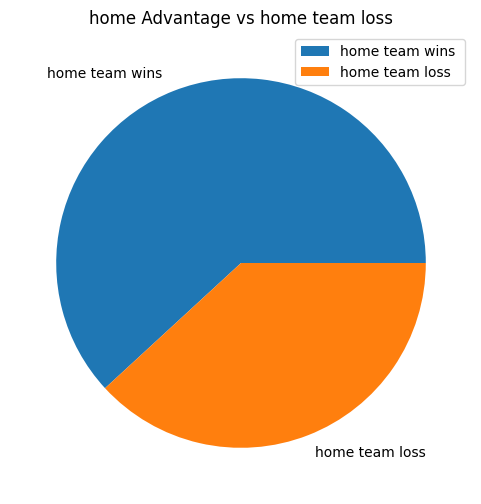

In [101]:
home_advantage.mean(numeric_only=True).plot(kind='pie',title='home Advantage vs home team loss',labels=['home team wins ','home team loss'],figsize=(6,6))
plt.legend();

In [102]:
#which teams has most wins
home_team=df[['date','home_team','home_team_score','away_team_score']]
home_team.head(15)

,date,home_team,home_team_score,away_team_score
0,1993-08-08,Bolivia,3,1
1,1993-08-08,Brazil,1,1
2,1993-08-08,Ecuador,5,0
3,1993-08-08,Guinea,1,0
4,1993-08-08,Paraguay,1,3
5,1993-08-08,Peru,0,1
6,1993-08-08,Zimbabwe,2,0
7,1993-08-09,Guinea,4,0
8,1993-08-11,Faroe Islands,0,7
9,1993-08-11,Sweden,1,2


In [103]:
home_team['home_team_score']>home_team['away_team_score']
homewins=home_team.loc[hometeam['home_team_score']>home_team['away_team_score']]
homewins.head()

,date,home_team,home_team_score,away_team_score
0,1993-08-08,Bolivia,3,1
2,1993-08-08,Ecuador,5,0
3,1993-08-08,Guinea,1,0
6,1993-08-08,Zimbabwe,2,0
7,1993-08-09,Guinea,4,0


In [104]:
home_team['home_team_score']<home_team['away_team_score']
homeloss=home_team.loc[home_team['home_team_score']<home_team['away_team_score']]
homeloss.head(15)

,date,home_team,home_team_score,away_team_score
4,1993-08-08,Paraguay,1,3
5,1993-08-08,Peru,0,1
8,1993-08-11,Faroe Islands,0,7
9,1993-08-11,Sweden,1,2
26,1993-08-31,Iceland,0,1
27,1993-09-05,Argentina,0,5
29,1993-09-05,Ecuador,0,1
30,1993-09-05,Estonia,0,2
32,1993-09-06,Eswatini,0,1
33,1993-09-08,Albania,0,1


In [105]:
hometeam_wins = homewins[['date', 'home_team', 'home_team_score', 'away_team_score']].rename(columns={'home_team': 'team', 'home_team_score': 'Home_team_win', 'away_team_score': 'away_team_win'})

# home_loss contains matches where the away team won. We extract these and rename the away team to 'team'
away_wins = homeloss[['date', 'home_team', 'home_team_score', 'away_team_score']].rename(columns={'home_team': 'team', 'home_team_score': 'Home_team_win', 'away_team_score': 'away_team_win'})

Team_streak = pd.concat([hometeam_wins, away_wins], ignore_index=True)
Team_streak

,date,team,Home_team_win,away_team_win
0,1993-08-08,Bolivia,3,1
1,1993-08-08,Ecuador,5,0
2,1993-08-08,Guinea,1,0
3,1993-08-08,Zimbabwe,2,0
4,1993-08-09,Guinea,4,0
...,...,...,...,...
18209,2022-06-14,Poland,0,1
18210,2022-06-14,Armenia,1,4
18211,2022-06-14,Romania,0,3
18212,2022-06-14,Liechtenstein,0,2


In [106]:
# Q7: Top 10 teams with the longest consecutive win streak
all_teams = sorted(set(df['home_team']).union(df['away_team']))

def longest_win_streak(team):
    matches = df[(df['home_team'] == team) | (df['away_team'] == team)].copy()
    matches = matches.sort_values('date')
    current = 0
    longest = 0
    for _, match in matches.iterrows():
        won = (
            (match['home_team'] == team and match['home_team_score'] > match['away_team_score'])
            or
            (match['away_team'] == team and match['away_team_score'] > match['home_team_score'])
        )
        if won:
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest

win_streaks = pd.DataFrame({
    'Team': all_teams,
    'Longest Win Streak': [longest_win_streak(t) for t in all_teams]
}).sort_values('Longest Win Streak', ascending=False).reset_index(drop=True)

top_10_win_streak = win_streaks.head(10)
top_10_win_streak


,Team,Longest Win Streak
0,Spain,15
1,France,14
2,Brazil,14
3,Italy,13
4,Australia,13
5,Belgium,12
6,Morocco,12
7,United Arab Emirates,11
8,Saudi Arabia,11
9,Russia,11


In [107]:
# Q3 helper: determine the winner of a match
def victory(team1, team2, team1_rank, team2_rank, team1_score, team2_score):
    if team1_score > team2_score:
        return team1
    elif team1_score == team2_score:
        return "Draw"
    else:
        return team2


In [108]:
# Create a winner column for every match
df['winner'] = df.apply(
    lambda x: victory(
        x['home_team'], x['away_team'],
        x['home_team_fifa_rank'], x['away_team_fifa_rank'],
        x['home_team_score'], x['away_team_score']
    ),
    axis=1
)
df[['home_team', 'away_team', 'home_team_score', 'away_team_score', 'winner']].head()


,home_team,away_team,home_team_score,away_team_score,winner
0,Bolivia,Uruguay,3,1,Bolivia
1,Brazil,Mexico,1,1,Draw
2,Ecuador,Venezuela,5,0,Ecuador
3,Guinea,Sierra Leone,1,0,Guinea
4,Paraguay,Argentina,1,3,Argentina


In [109]:
def rank(home,away,rank_home,rank_away):
  if rank_home<rank_away:
    return home
  else:
    return away

In [110]:
def rank(home, away, rank_home, rank_away):
    if rank_home < rank_away:
        return home
    else:
        return away

df['better_rank'] = df.apply(lambda x: rank(x['home_team'], x['away_team'], x['home_team_fifa_rank'], x['away_team_fifa_rank']), axis=1)

In [111]:
def result_rank(winner, better_rank):
    if winner == "Draw":
        return "Draw"
    if winner == better_rank:
        return 'highest'
    else:
        return 'smallest'

In [112]:
df['result_rank'] = df.apply(lambda x: result_rank(x['winner'], x['better_rank']), axis=1)
df['result_rank'].value_counts(normalize=True) * 100

,proportion
result_rank,
highest,54.893190
Draw,23.857698
smallest,21.249112


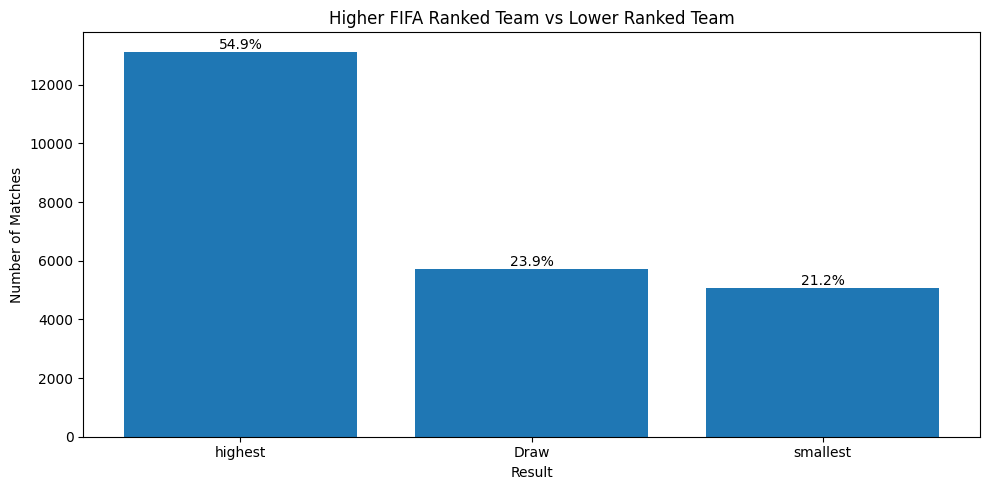

In [113]:
# Q3 visualization
result_counts = df['result_rank'].value_counts()
plt.figure(figsize=(10,5))
bars = plt.bar(result_counts.index.astype(str), result_counts.values)
total = result_counts.sum()
for bar, value in zip(bars, result_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value/total*100:.1f}%',
             ha='center', va='bottom')
plt.title('Higher FIFA Ranked Team vs Lower Ranked Team')
plt.xlabel('Result')
plt.ylabel('Number of Matches')
plt.tight_layout()
plt.show()


In [114]:
#what is the  percentage comparing when the highest attack rank plays with the lowest attack rank
df_rank_attack=df[df['home_team_mean_offense_score'].notnull()]

In [115]:
df_rank_attack=df[df['away_team_mean_offense_score'].notnull()]

In [116]:
def rank_attack(home,away,rank_home,rank_away):
  if rank_home>rank_away:
    return home
  else:
    return away


In [117]:
# Cleanly slice and copy to avoid SettingWithCopyWarning
df_rank_attack = df[df['home_team_mean_offense_score'].notnull() & df['away_team_mean_offense_score'].notnull()].copy()

# Map the team with the higher (better) offense score
df_rank_attack['better_attack'] = df_rank_attack.apply(
    lambda x: rank_attack(x['home_team'], x['away_team'], x['home_team_mean_offense_score'], x['away_team_mean_offense_score']),
    axis=1
)

# Determine if the team with the better attack won, drew, or lost
def result_attack_win(winner, better_attack):
    if winner == "Draw":
        return "Draw"
    elif winner == better_attack:
        return "Better Attack Wins"
    else:
        return "Lower Attack Wins"

df_rank_attack['attack_result'] = df_rank_attack.apply(
    lambda x: result_attack_win(x['winner'], x['better_attack']),
    axis=1
)

# Calculate and print the percentage distribution
print(df_rank_attack['attack_result'].value_counts(normalize=True) * 100)

attack_result
Better Attack Wins    47.535638
Lower Attack Wins     28.606664
Draw                  23.857698
Name: proportion, dtype: float64


In [118]:
df_rank_attack['result_attack']=df_rank_attack.apply(lambda x:result_rank(x['winner'],x['better_attack']),axis=1)

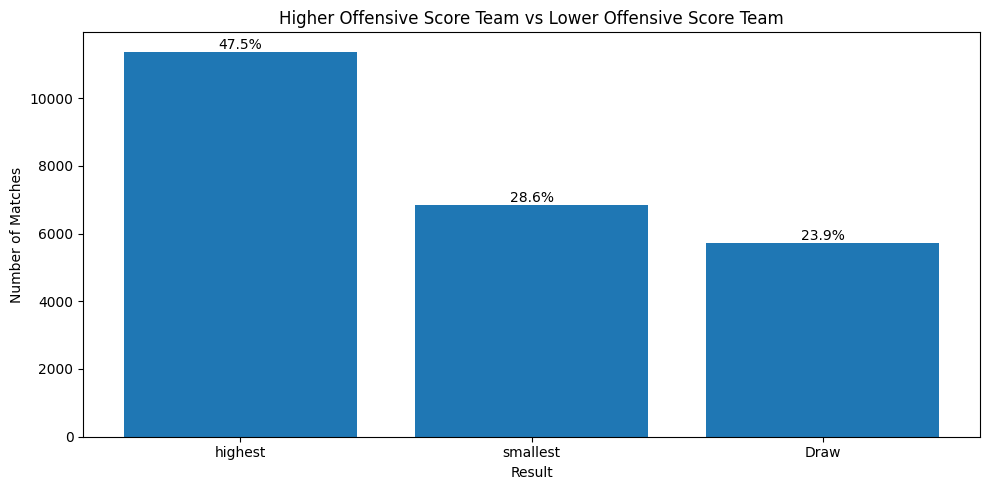

In [119]:
# Q4 visualization
result_counts_attack = df_rank_attack['result_attack'].value_counts()
plt.figure(figsize=(10,5))
bars = plt.bar(result_counts_attack.index.astype(str), result_counts_attack.values)
total_attack = result_counts_attack.sum()
for bar, value in zip(bars, result_counts_attack.values):
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value/total_attack*100:.1f}%',
             ha='center', va='bottom')
plt.title('Higher Offensive Score Team vs Lower Offensive Score Team')
plt.xlabel('Result')
plt.ylabel('Number of Matches')
plt.tight_layout()
plt.show()


In [120]:
# do teams with stronger offensive players score more goals? and do teams with stronger goalkeeper receive fewer goals
offence_score=[]

for x in wc_2022:
  of_score=np.round((df[df['home_team']==x]["home_team_mean_offense_score"].mean()+df[df['away_team']==x]['away_team_mean_offense_score'].mean())/2,2)
  offence_score.append(of_score)
offence_scores=pd.DataFrame({'Team':wc_2022,'of score':offence_score}).sort_values('of score',ascending=False).reset_index(drop=True)
offence_scores.index+=1
offence_scores

,Team,of score
1,Argentina,83.56
2,Spain,82.46
3,France,81.96
4,Netherlands,81.93
5,Portugal,81.85
6,England,81.74
7,Brazil,81.73
8,Uruguay,80.61
9,Germany,80.47
10,Belgium,79.53


In [121]:
import pandas as pd
import numpy as np

data_path = ('/content/international_matches (2).csv' if os.path.exists('/content/international_matches (2).csv') else '/mnt/data/international_matches (2).csv')
df = pd.read_csv(data_path)

wc_2022 = ['Qatar', 'Ecuador', 'Senegal', 'Netherlands', 'England', 'Iran', 'USA', 'Wales', 'Argentina', 'Saudi Arabia', 'Mexico', 'Poland', 'France', 'Australia', 'Denmark', 'Tunisia', 'Spain', 'Costa Rica', 'Germany', 'Japan', 'Belgium', 'Canada', 'Morocco', 'Croatia', 'Brazil', 'Serbia', 'Switzerland', 'Cameroon', 'Portugal', 'Ghana', 'Uruguay', 'Korea Republic']

goals_conceded_home, goals_scored_home, goals_conceded_away, goals_scored_away = [], [], [], []
total_goals_scored, total_goals_conceded = [], []

for team in wc_2022:
    gch = df[df['home_team'] == team]['away_team_score'].sum()
    gsh = df[df['home_team'] == team]['home_team_score'].sum()
    gca = df[df['away_team'] == team]['home_team_score'].sum()
    gsa = df[df['away_team'] == team]['away_team_score'].sum()

    tgc = np.add(gch, gca)
    tgs = np.add(gsh, gsa)

    goals_conceded_home.append(gch)
    goals_scored_home.append(gsh)
    goals_conceded_away.append(gca)
    goals_scored_away.append(gsa)
    total_goals_scored.append(tgs)
    total_goals_conceded.append(tgc)

goals = pd.DataFrame({
    'Team': wc_2022,
    'Scored goals home': goals_scored_home,
    'Scored goals away': goals_scored_away,
    'Conceded goals home': goals_conceded_home,
    'Conceded goals away': goals_conceded_away,
    'Total scored goals': total_goals_scored,
    'Total conceded goals': total_goals_conceded
})

goals['Goal difference'] = goals['Total scored goals'] - goals['Total conceded goals']
goals['Goal ratio'] = goals['Total scored goals'] / goals['Total conceded goals']

goals = goals.sort_values('Goal difference', ascending=False).reset_index(drop=True)
goals.index += 1
goals

,Team,Scored goals home,Scored goals away,Conceded goals home,Conceded goals away,Total scored goals,Total conceded goals,Goal difference,Goal ratio
1,Brazil,558,396,141,159,954,300,654,3.180000
2,Spain,469,312,107,141,781,248,533,3.149194
3,Germany,544,331,220,171,875,391,484,2.237852
4,Netherlands,426,274,145,142,700,287,413,2.439024
5,France,447,223,154,112,670,266,404,2.518797
6,Portugal,424,244,124,144,668,268,400,2.492537
7,England,384,246,132,119,630,251,379,2.509960
8,Japan,533,243,273,153,776,426,350,1.821596
9,Mexico,572,286,272,247,858,519,339,1.653179
10,Australia,435,194,127,164,629,291,338,2.161512


In [122]:
# Q5: compare offensive strength with total goals scored
offence_player_vs_goals_scored = offence_scores.merge(
    goals[['Team', 'Total scored goals']],
    on='Team',
    how='left'
)
offence_player_vs_goals_scored


,Team,of score,Total scored goals
0,Argentina,83.56,657.0
1,Spain,82.46,781.0
2,France,81.96,670.0
3,Netherlands,81.93,700.0
4,Portugal,81.85,668.0
5,England,81.74,630.0
6,Brazil,81.73,954.0
7,Uruguay,80.61,504.0
8,Germany,80.47,875.0
9,Belgium,79.53,563.0


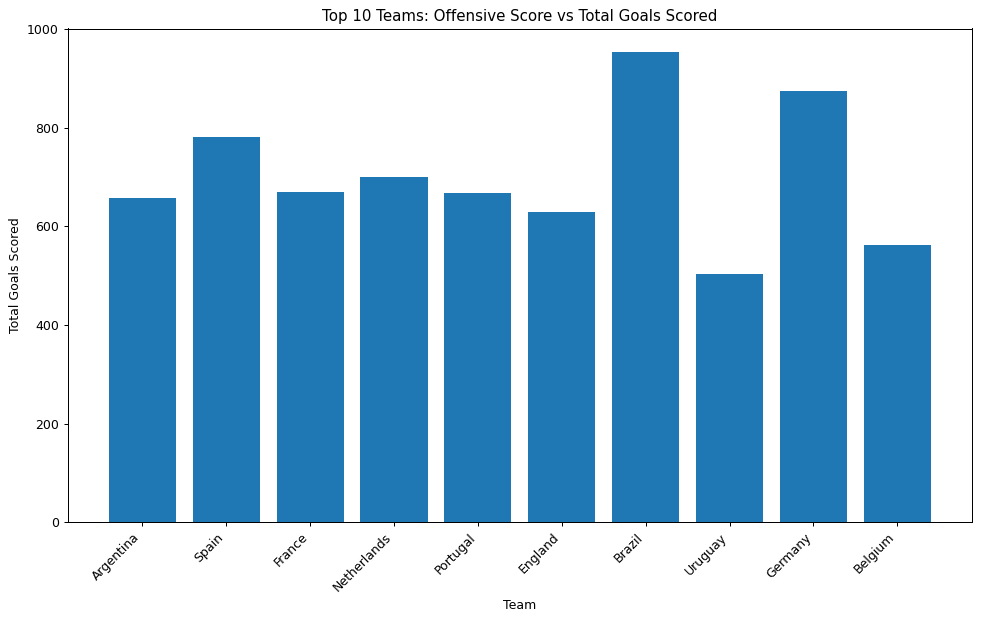

In [123]:
# Q5 visualization
plt.figure(figsize=(11, 7), dpi=90)
plot_data = offence_player_vs_goals_scored.head(10)
bars = plt.bar(plot_data['Team'], plot_data['Total scored goals'])
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Teams: Offensive Score vs Total Goals Scored')
plt.xlabel('Team')
plt.ylabel('Total Goals Scored')
plt.tight_layout()
plt.show()


## Q6 - Do teams with stronger goalkeepers receive fewer goals?

In [124]:
# Q6: compare average goalkeeper score with average goals conceded per match
def team_average_score(home_col, away_col):
    home_part = df[['home_team', home_col]].rename(columns={'home_team': 'Team', home_col: 'Score'})
    away_part = df[['away_team', away_col]].rename(columns={'away_team': 'Team', away_col: 'Score'})
    return pd.concat([home_part, away_part]).groupby('Team')['Score'].mean()

goalkeeper_scores = team_average_score(
    'home_team_goalkeeper_score',
    'away_team_goalkeeper_score'
)

goals_conceded = pd.concat([
    df[['home_team', 'away_team_score']].rename(
        columns={'home_team': 'Team', 'away_team_score': 'Goals Conceded'}
    ),
    df[['away_team', 'home_team_score']].rename(
        columns={'away_team': 'Team', 'home_team_score': 'Goals Conceded'}
    )
]).groupby('Team')['Goals Conceded'].mean()

q6 = pd.DataFrame({
    'Goalkeeper Score': goalkeeper_scores,
    'Average Goals Conceded': goals_conceded
}).reindex(wc_2022).dropna()

correlation_q6 = q6['Goalkeeper Score'].corr(q6['Average Goals Conceded'])
print(f"Correlation between goalkeeper score and average goals conceded: {correlation_q6:.3f}")
print("A negative correlation means stronger goalkeeper scores are associated with fewer goals conceded.")
q6.sort_values('Goalkeeper Score', ascending=False)


Correlation between goalkeeper score and average goals conceded: -0.372
A negative correlation means stronger goalkeeper scores are associated with fewer goals conceded.


,Goalkeeper Score,Average Goals Conceded
Team,,
Germany,89.053719,1.002564
Spain,88.784810,0.700565
France,86.868085,0.718919
Brazil,86.261224,0.692841
England,83.240741,0.751497
Netherlands,83.232877,0.844118
Belgium,82.443299,1.100334
Poland,82.105023,1.132948
Portugal,81.809735,0.797619


## Q7 - Top 10 teams with the longest win streak

In [125]:
# Q7 result
top_10_win_streak


,Team,Longest Win Streak
0,Spain,15
1,France,14
2,Brazil,14
3,Italy,13
4,Australia,13
5,Belgium,12
6,Morocco,12
7,United Arab Emirates,11
8,Saudi Arabia,11
9,Russia,11


## Q8 - Better team win percentage: home or away?

In [126]:
# Q8: compare each 2022 World Cup team's home and away win percentage
q8_rows = []
for team in wc_2022:
    home_games = df[df['home_team'] == team]
    away_games = df[df['away_team'] == team]

    home_win_pct = (
        (home_games['home_team_score'] > home_games['away_team_score']).mean() * 100
        if len(home_games) else np.nan
    )
    away_win_pct = (
        (away_games['away_team_score'] > away_games['home_team_score']).mean() * 100
        if len(away_games) else np.nan
    )

    q8_rows.append([team, home_win_pct, away_win_pct, len(home_games), len(away_games)])

home_away_win_pct = pd.DataFrame(
    q8_rows,
    columns=['Team', 'Home Win %', 'Away Win %', 'Home Games', 'Away Games']
)

home_away_win_pct['Better Venue'] = np.where(
    home_away_win_pct['Home Win %'] >= home_away_win_pct['Away Win %'],
    'Home',
    'Away'
)

print(f"Average home win percentage: {home_away_win_pct['Home Win %'].mean():.2f}%")
print(f"Average away win percentage: {home_away_win_pct['Away Win %'].mean():.2f}%")
home_away_win_pct.sort_values('Home Win %', ascending=False)


Average home win percentage: 59.03%
Average away win percentage: 40.73%


,Team,Home Win %,Away Win %,Home Games,Away Games,Better Venue
24,Brazil,75.536481,58.000000,233,200,Home
16,Spain,75.132275,60.000000,189,165,Home
8,Argentina,67.368421,47.457627,190,177,Home
28,Portugal,66.304348,48.026316,184,152,Home
13,Australia,65.088757,36.231884,169,138,Home
12,France,64.253394,57.046980,221,149,Home
22,Morocco,63.730570,34.615385,193,130,Home
4,England,63.402062,50.000000,194,140,Home
2,Senegal,63.333333,32.571429,150,175,Home
18,Germany,62.557078,58.479532,219,171,Home


## Q9 - Which team has the best goalkeeper, defense, midfield and offense?

In [127]:
# Q9: average FIFA team attribute scores for the 2022 World Cup teams
q9 = pd.DataFrame({
    'Goalkeeper': team_average_score('home_team_goalkeeper_score', 'away_team_goalkeeper_score'),
    'Defense': team_average_score('home_team_mean_defense_score', 'away_team_mean_defense_score'),
    'Midfield': team_average_score('home_team_mean_midfield_score', 'away_team_mean_midfield_score'),
    'Offense': team_average_score('home_team_mean_offense_score', 'away_team_mean_offense_score')
}).reindex(wc_2022)

print("Best goalkeeper:", q9['Goalkeeper'].idxmax(), f"({q9['Goalkeeper'].max():.2f})")
print("Strongest defense:", q9['Defense'].idxmax(), f"({q9['Defense'].max():.2f})")
print("Strongest midfield:", q9['Midfield'].idxmax(), f"({q9['Midfield'].max():.2f})")
print("Strongest offense:", q9['Offense'].idxmax(), f"({q9['Offense'].max():.2f})")

q9.sort_values('Offense', ascending=False)


Best goalkeeper: Germany (89.05)
Strongest defense: Brazil (85.92)
Strongest midfield: Spain (87.13)
Strongest offense: Argentina (88.26)


,Goalkeeper,Defense,Midfield,Offense
Team,,,,
Argentina,80.693966,82.981897,84.428017,88.260345
Brazil,86.261224,85.920408,85.343673,86.531020
Spain,88.784810,85.509283,87.127848,85.874684
France,86.868085,84.081277,86.158723,85.700000
Netherlands,83.232877,80.734703,83.709132,85.478539
England,83.240741,84.693056,84.511111,85.118981
Portugal,81.809735,82.891593,83.590265,84.933628
Germany,89.053719,84.688843,85.796694,83.602066
Uruguay,79.360190,79.646445,78.514692,83.577251


## Q10 - Top 15 teams with the highest win percentage

In [128]:
# Q10: win percentage among the 2022 World Cup teams available in the dataset
q10_rows = []
for team in wc_2022:
    home_games = df[df['home_team'] == team]
    away_games = df[df['away_team'] == team]

    wins = (
        (home_games['home_team_score'] > home_games['away_team_score']).sum()
        + (away_games['away_team_score'] > away_games['home_team_score']).sum()
    )
    games = len(home_games) + len(away_games)

    if games > 0:
        q10_rows.append([team, int(wins), int(games), wins / games * 100])

top_15_win_percentage = pd.DataFrame(
    q10_rows,
    columns=['Team', 'Wins', 'Games', 'Win %']
).sort_values('Win %', ascending=False).head(15).reset_index(drop=True)

top_15_win_percentage.index += 1
top_15_win_percentage


,Team,Wins,Games,Win %
1,Spain,241,354,68.079096
2,Brazil,292,433,67.436490
3,France,227,370,61.351351
4,Germany,237,390,60.769231
5,Netherlands,199,340,58.529412
6,Portugal,195,336,58.035714
7,England,193,334,57.784431
8,Argentina,212,367,57.765668
9,Belgium,158,299,52.842809
10,Croatia,168,320,52.500000


## Q11 - FIFA World Cup 2026 winner prediction

In [129]:
# Q11: historical/model-based World Cup 2026 prediction
# IMPORTANT: the supplied dataset ends on 2022-06-14, so this is NOT a prediction
# based on actual 2026 results. It ranks the 2022 World Cup teams using only
# historical information contained in the supplied dataset.

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Build match-level features using ranking, FIFA points and team attribute differences.
feature_cols = [
    'home_team_fifa_rank', 'away_team_fifa_rank',
    'home_team_total_fifa_points', 'away_team_total_fifa_points',
    'home_team_goalkeeper_score', 'away_team_goalkeeper_score',
    'home_team_mean_defense_score', 'away_team_mean_defense_score',
    'home_team_mean_offense_score', 'away_team_mean_offense_score',
    'home_team_mean_midfield_score', 'away_team_mean_midfield_score'
]

model_df = df[feature_cols + ['home_team_score', 'away_team_score']].copy()
model_df['target'] = (model_df['home_team_score'] > model_df['away_team_score']).astype(int)

X = model_df[feature_cols].copy()
y = model_df['target']

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=2000))
])
model.fit(X, y)

# Team strength from historical win %, goal difference per match, FIFA ranking,
# and average player/position scores.
team_summary = []
for team in wc_2022:
    home = df[df['home_team'] == team]
    away = df[df['away_team'] == team]
    games = len(home) + len(away)

    if games == 0:
        continue

    wins = (
        (home['home_team_score'] > home['away_team_score']).sum()
        + (away['away_team_score'] > away['home_team_score']).sum()
    )
    goals_for = home['home_team_score'].sum() + away['away_team_score'].sum()
    goals_against = home['away_team_score'].sum() + away['home_team_score'].sum()

    team_summary.append({
        'Team': team,
        'Win %': wins / games * 100,
        'Goal Difference/Game': (goals_for - goals_against) / games,
        'FIFA Rank': pd.concat([
            home['home_team_fifa_rank'],
            away['away_team_fifa_rank']
        ]).mean(),
        'FIFA Points': pd.concat([
            home['home_team_total_fifa_points'],
            away['away_team_total_fifa_points']
        ]).mean(),
        'Goalkeeper': goalkeeper_scores.get(team, np.nan),
        'Defense': team_average_score(
            'home_team_mean_defense_score',
            'away_team_mean_defense_score'
        ).get(team, np.nan),
        'Midfield': team_average_score(
            'home_team_mean_midfield_score',
            'away_team_mean_midfield_score'
        ).get(team, np.nan),
        'Offense': team_average_score(
            'home_team_mean_offense_score',
            'away_team_mean_offense_score'
        ).get(team, np.nan)
    })

team_strength = pd.DataFrame(team_summary).dropna()

# Convert metrics to comparable 0-100 percentile scores.
team_strength['Rank Score'] = (
    team_strength['FIFA Rank'].rank(ascending=False, pct=True) * 100
)
team_strength['Win Score'] = team_strength['Win %'].rank(pct=True) * 100
team_strength['Goal Diff Score'] = (
    team_strength['Goal Difference/Game'].rank(pct=True) * 100
)
team_strength['FIFA Points Score'] = (
    team_strength['FIFA Points'].rank(pct=True) * 100
)

team_strength['Composite Score'] = (
    0.25 * team_strength['Win Score']
    + 0.20 * team_strength['Goal Diff Score']
    + 0.20 * team_strength['Rank Score']
    + 0.10 * team_strength['FIFA Points Score']
    + 0.10 * team_strength['Goalkeeper'].rank(pct=True) * 100
    + 0.05 * team_strength['Defense'].rank(pct=True) * 100
    + 0.05 * team_strength['Midfield'].rank(pct=True) * 100
    + 0.05 * team_strength['Offense'].rank(pct=True) * 100
)

prediction_ranking = team_strength.sort_values(
    'Composite Score', ascending=False
).reset_index(drop=True)

prediction_ranking.index += 1

print("Historical/model-based top candidates:")
display(prediction_ranking[
    ['Team', 'Composite Score', 'Win %', 'FIFA Rank',
     'Goal Difference/Game', 'Goalkeeper', 'Defense', 'Midfield', 'Offense']
].head(10))

print(
    f"Predicted winner from this historical dataset: "
    f"{prediction_ranking.iloc[0]['Team']}"
)


Historical/model-based top candidates:


,Team,Composite Score,Win %,FIFA Rank,Goal Difference/Game,Goalkeeper,Defense,Midfield,Offense
1,Spain,97.166667,68.079096,5.418079,1.505650,88.784810,85.509283,87.127848,85.874684
2,Brazil,93.166667,67.436490,3.145497,1.510393,86.261224,85.920408,85.343673,86.531020
3,Germany,90.500000,60.769231,6.474359,1.241026,89.053719,84.688843,85.796694,83.602066
4,France,86.000000,61.351351,8.240541,1.091892,86.868085,84.081277,86.158723,85.700000
5,England,83.833333,57.784431,9.904192,1.134731,83.240741,84.693056,84.511111,85.118981
6,Netherlands,82.333333,58.529412,9.926471,1.214706,83.232877,80.734703,83.709132,85.478539
7,Portugal,81.666667,58.035714,10.244048,1.190476,81.809735,82.891593,83.590265,84.933628
8,Argentina,80.500000,57.765668,6.318801,0.885559,80.693966,82.981897,84.428017,88.260345
9,Belgium,71.000000,52.842809,24.525084,0.782609,82.443299,81.236082,81.532990,81.723196
10,Croatia,65.833333,52.500000,18.965625,0.718750,78.676329,78.809662,81.202415,80.085507


Predicted winner from this historical dataset: Spain


### Dataset limitation
The supplied `international_matches (2).csv` contains matches only through **14 June 2022**. Therefore Q11 is a historical/model-based ranking and should not be presented as an actual 2026 result prediction using post-2022 data.

# FINAL PROJECT — FIFA WORLD CUP 2026 ANALYSIS & PREDICTION

## FIFA Oracle: Data Analysis of International Football Matches

This section implements the requested hands-on lab questions in a clean **Q1–Q10** format.

### Project goals
1. Find the team with the most wins.
2. Compare the higher-ranked team with the lower-ranked team.
3. Compare stronger and weaker offensive teams.
4. Test whether stronger offense is associated with more goals.
5. Test whether stronger goalkeepers are associated with fewer goals conceded.
6. Find the longest winning streak.
7. Compare home and away win percentages.
8. Identify the best goalkeeper, defense, midfield and offense.
9. Identify teams with high win percentages.
10. Produce a **model-based FIFA World Cup 2026 winner prediction**.

> **Important data note:** The supplied international-match dataset ends on **14 June 2022**. Therefore the 2026 prediction is a historical/model-based prediction using the information available in this dataset. It is not a claim about actual 2026 match results.

In [130]:
# ============================================================
# PROJECT SETUP
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the same dataset used by the original notebook.
DATA_PATHS = [
    "/content/international_matches (2).csv",
    "/mnt/data/international_matches (2).csv"
]

DATA_PATH = next((p for p in DATA_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Please upload 'international_matches (2).csv' to Colab/runtime before running this notebook."
    )

raw = pd.read_csv(DATA_PATH)
raw["date"] = pd.to_datetime(raw["date"])

print("Dataset shape:", raw.shape)
print("Date range:", raw["date"].min().date(), "to", raw["date"].max().date())
display(raw.head())

Dataset shape: (23921, 25)
Date range: 1993-08-08 to 2022-06-14


,date,home_team,away_team,home_team_continent,away_team_continent,home_team_fifa_rank,away_team_fifa_rank,home_team_total_fifa_points,away_team_total_fifa_points,home_team_score,...,shoot_out,home_team_result,home_team_goalkeeper_score,away_team_goalkeeper_score,home_team_mean_defense_score,home_team_mean_offense_score,home_team_mean_midfield_score,away_team_mean_defense_score,away_team_mean_offense_score,away_team_mean_midfield_score
0,1993-08-08,Bolivia,Uruguay,South America,South America,59,22,0,0,3,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1993-08-08,Brazil,Mexico,South America,North America,8,14,0,0,1,...,No,Draw,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1993-08-08,Ecuador,Venezuela,South America,South America,35,94,0,0,5,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1993-08-08,Guinea,Sierra Leone,Africa,Africa,65,86,0,0,1,...,No,Win,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1993-08-08,Paraguay,Argentina,South America,South America,67,5,0,0,1,...,No,Lose,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [131]:
# ============================================================
# DATA PREPARATION
# ============================================================
dfp = raw.copy()

# Keep numeric attribute scores missing where they were originally missing.
# We calculate team-level attribute averages using available observations.
score_cols = [
    "home_team_goalkeeper_score", "away_team_goalkeeper_score",
    "home_team_mean_defense_score", "away_team_mean_defense_score",
    "home_team_mean_midfield_score", "away_team_mean_midfield_score",
    "home_team_mean_offense_score", "away_team_mean_offense_score"
]

# Create a unified team-match table so every team can be analyzed
# from both home and away appearances.
home = pd.DataFrame({
    "date": dfp["date"],
    "team": dfp["home_team"],
    "opponent": dfp["away_team"],
    "team_rank": dfp["home_team_fifa_rank"],
    "opponent_rank": dfp["away_team_fifa_rank"],
    "team_points": dfp["home_team_total_fifa_points"],
    "opponent_points": dfp["away_team_total_fifa_points"],
    "goals_for": dfp["home_team_score"],
    "goals_against": dfp["away_team_score"],
    "result": dfp["home_team_result"],
    "is_home": 1,
    "goalkeeper": dfp["home_team_goalkeeper_score"],
    "defense": dfp["home_team_mean_defense_score"],
    "midfield": dfp["home_team_mean_midfield_score"],
    "offense": dfp["home_team_mean_offense_score"],
})

away_result = np.select(
    [
        dfp["home_team_result"].eq("Lose"),
        dfp["home_team_result"].eq("Win"),
        dfp["home_team_result"].eq("Draw")
    ],
    ["Win", "Lose", "Draw"],
    default="None"
)

away = pd.DataFrame({
    "date": dfp["date"],
    "team": dfp["away_team"],
    "opponent": dfp["home_team"],
    "team_rank": dfp["away_team_fifa_rank"],
    "opponent_rank": dfp["home_team_fifa_rank"],
    "team_points": dfp["away_team_total_fifa_points"],
    "opponent_points": dfp["home_team_total_fifa_points"],
    "goals_for": dfp["away_team_score"],
    "goals_against": dfp["home_team_score"],
    "result": away_result,
    "is_home": 0,
    "goalkeeper": dfp["away_team_goalkeeper_score"],
    "defense": dfp["away_team_mean_defense_score"],
    "midfield": dfp["away_team_mean_midfield_score"],
    "offense": dfp["away_team_mean_offense_score"],
})

team_matches = pd.concat([home, away], ignore_index=True)
team_matches = team_matches.sort_values(["team", "date"]).reset_index(drop=True)

print("Team-match records:", len(team_matches))
display(team_matches.head())

Team-match records: 47842


,date,team,opponent,team_rank,opponent_rank,team_points,opponent_points,goals_for,goals_against,result,is_home,goalkeeper,defense,midfield,offense
0,2003-03-16,Afghanistan,Kyrgyz Republic,203,174,0,0,2,1,Win,0,NaN,NaN,NaN,NaN
1,2003-03-18,Afghanistan,Nepal,203,163,0,0,0,4,Lose,0,NaN,NaN,NaN,NaN
2,2003-11-19,Afghanistan,Turkmenistan,198,122,0,0,0,11,Lose,0,NaN,NaN,NaN,NaN
3,2003-11-23,Afghanistan,Turkmenistan,198,122,0,0,0,2,Lose,1,NaN,NaN,NaN,NaN
4,2005-11-09,Afghanistan,Tajikistan,199,143,0,0,0,4,Lose,0,NaN,NaN,NaN,NaN


# Q1 — Which team has the most wins?

A win is counted from the perspective of each team. Draws are not counted as wins.

The result below shows the complete ranking so it is clear which team is first and how the other teams compare.

Q1 ANSWER: Brazil has the most wins with 301 wins.


,team,Wins,Matches,Goals_For,Goals_Against,Win_Percentage,Goal_Difference
0,Brazil,301,433,954,300,69.515012,654
1,Mexico,272,517,858,519,52.611219,339
2,Spain,246,354,781,248,69.491525,533
3,USA,242,464,761,452,52.155172,309
4,Germany,240,390,875,391,61.538462,484
5,Saudi Arabia,238,471,762,485,50.530786,277
6,France,230,370,670,266,62.162162,404
7,Japan,227,425,776,426,53.411765,350
8,IR Iran,217,366,713,280,59.289617,433
9,Korea Republic,217,436,685,413,49.770642,272


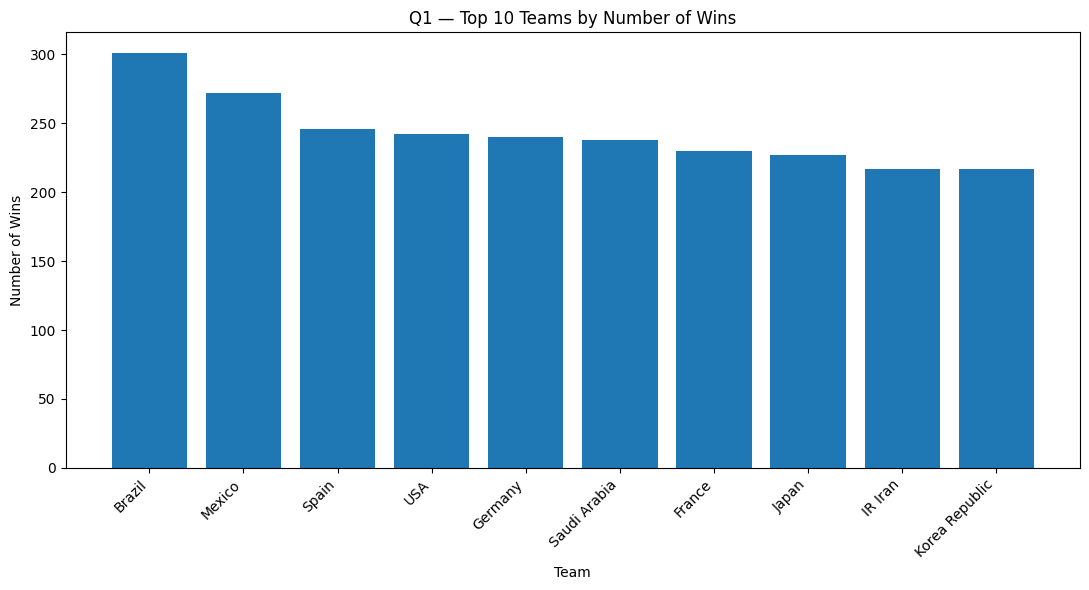

In [132]:
# ============================================================
# Q1 — MOST WINS
# ============================================================
q1 = (
    team_matches.assign(win=(team_matches["result"] == "Win").astype(int))
    .groupby("team", as_index=False)
    .agg(
        Wins=("win", "sum"),
        Matches=("team", "size"),
        Goals_For=("goals_for", "sum"),
        Goals_Against=("goals_against", "sum")
    )
)

q1["Win_Percentage"] = 100 * q1["Wins"] / q1["Matches"]
q1["Goal_Difference"] = q1["Goals_For"] - q1["Goals_Against"]
q1 = q1.sort_values(["Wins", "Win_Percentage"], ascending=False).reset_index(drop=True)

winner_q1 = q1.iloc[0]

print(f"Q1 ANSWER: {winner_q1['team']} has the most wins with {int(winner_q1['Wins'])} wins.")
display(q1.head(15))

plt.figure(figsize=(11, 6))
plt.bar(q1.head(10)["team"], q1.head(10)["Wins"])
plt.title("Q1 — Top 10 Teams by Number of Wins")
plt.xlabel("Team")
plt.ylabel("Number of Wins")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Q2 — Winning percentage when the highest-ranked team plays the lowest-ranked team

For every match, the team with the **smaller FIFA rank number** is treated as the higher-ranked team because FIFA rank 1 is better than rank 20.

We compare:
- higher-ranked team wins,
- lower-ranked team wins,
- draw.

Q2 ANSWER: The higher-ranked team wins 55.61% of these matches.


,Outcome,Matches,Percentage
0,Higher-ranked team won,13303,55.612224
1,Draw,5389,22.528322
2,Lower-ranked team won,5229,21.859454


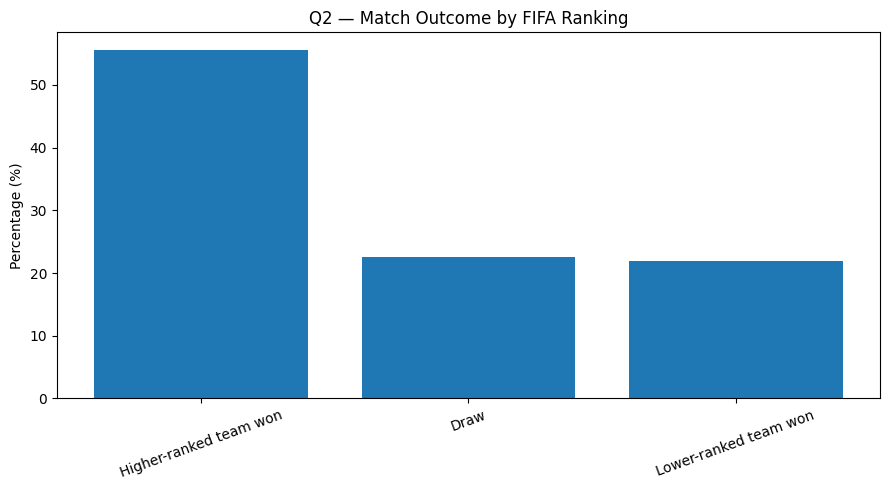

In [133]:
# ============================================================
# Q2 — HIGHER RANK VS LOWER RANK
# ============================================================
q2 = dfp[[
    "home_team", "away_team",
    "home_team_fifa_rank", "away_team_fifa_rank",
    "home_team_result"
]].copy()

q2["rank_favorite"] = np.where(
    q2["home_team_fifa_rank"] < q2["away_team_fifa_rank"],
    q2["home_team"], q2["away_team"]
)

q2["higher_rank_result"] = np.select(
    [
        q2["home_team_result"].eq("Draw"),
        q2["rank_favorite"].eq(q2["home_team"]) & q2["home_team_result"].eq("Win"),
        q2["rank_favorite"].eq(q2["away_team"]) & q2["home_team_result"].eq("Lose")
    ],
    ["Draw", "Higher-ranked team won", "Higher-ranked team won"],
    default="Lower-ranked team won"
)

q2_summary = (
    q2["higher_rank_result"].value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Matches")
)
q2_summary["Percentage"] = 100 * q2_summary["Matches"] / q2_summary["Matches"].sum()

higher_win_pct = float(
    q2_summary.loc[q2_summary["Outcome"] == "Higher-ranked team won", "Percentage"].iloc[0]
)

print(f"Q2 ANSWER: The higher-ranked team wins {higher_win_pct:.2f}% of these matches.")
display(q2_summary)

plt.figure(figsize=(9, 5))
plt.bar(q2_summary["Outcome"], q2_summary["Percentage"])
plt.title("Q2 — Match Outcome by FIFA Ranking")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Q3 — What is the winning percentage when the stronger attack plays the weaker attack?

The dataset contains **mean offense scores** for many matches. The team with the larger offense score is treated as the stronger attacking team.

Only matches where both teams have an offense score are included.

Q3 ANSWER: The stronger attacking team wins 51.33% of comparable matches.


,Outcome,Matches,Percentage
0,Stronger attack won,3098,51.333886
1,Draw,1499,24.838442
2,Weaker attack won,1438,23.827672


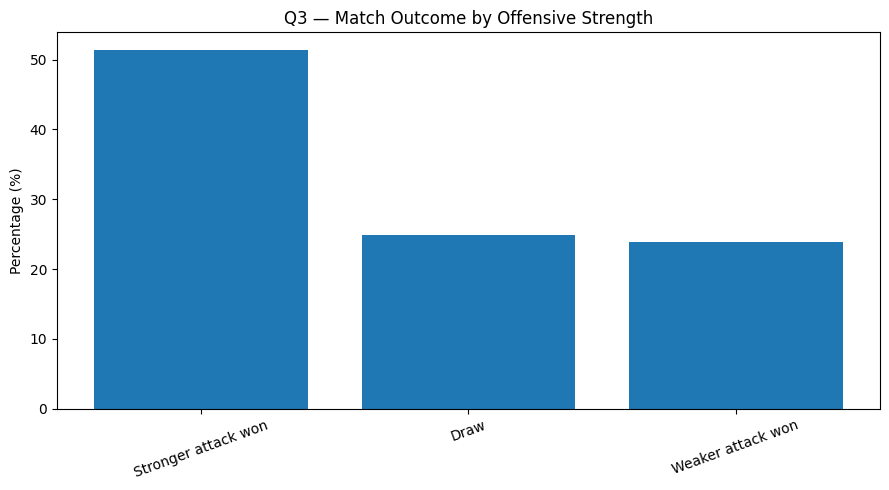

In [134]:
# ============================================================
# Q3 — STRONGER OFFENSE VS WEAKER OFFENSE
# ============================================================
q3 = dfp[[
    "home_team", "away_team",
    "home_team_mean_offense_score", "away_team_mean_offense_score",
    "home_team_result"
]].dropna().copy()

q3["stronger_attack"] = np.where(
    q3["home_team_mean_offense_score"] >= q3["away_team_mean_offense_score"],
    q3["home_team"], q3["away_team"]
)

q3["attack_result"] = np.select(
    [
        q3["home_team_result"].eq("Draw"),
        q3["stronger_attack"].eq(q3["home_team"]) & q3["home_team_result"].eq("Win"),
        q3["stronger_attack"].eq(q3["away_team"]) & q3["home_team_result"].eq("Lose")
    ],
    ["Draw", "Stronger attack won", "Stronger attack won"],
    default="Weaker attack won"
)

q3_summary = (
    q3["attack_result"].value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Matches")
)
q3_summary["Percentage"] = 100 * q3_summary["Matches"] / q3_summary["Matches"].sum()

strong_attack_pct = float(
    q3_summary.loc[q3_summary["Outcome"] == "Stronger attack won", "Percentage"].iloc[0]
)

print(f"Q3 ANSWER: The stronger attacking team wins {strong_attack_pct:.2f}% of comparable matches.")
display(q3_summary)

plt.figure(figsize=(9, 5))
plt.bar(q3_summary["Outcome"], q3_summary["Percentage"])
plt.title("Q3 — Match Outcome by Offensive Strength")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Q4 — Do teams with stronger offensive scores have more goals?

This question is answered in two ways:
1. A team-level table compares offense score with total goals scored.
2. Pearson correlation measures the strength and direction of the relationship.

A positive correlation means higher offense scores tend to be associated with more goals, while a correlation close to zero means a weak linear relationship.

Q4 ANSWER: Pearson correlation between offense score and total goals = 0.634
Interpretation: positive relationship


,team,Average_Offense_Score,Total_Goals_Scored
3,Argentina,88.260345,657
15,Brazil,86.531020,954
99,Spain,85.874684,781
40,France,85.700000,670
75,Netherlands,85.478539,700
58,Italy,85.263043,558
36,England,85.118981,630
86,Portugal,84.933628,668
44,Germany,83.602066,875
112,Uruguay,83.577251,504


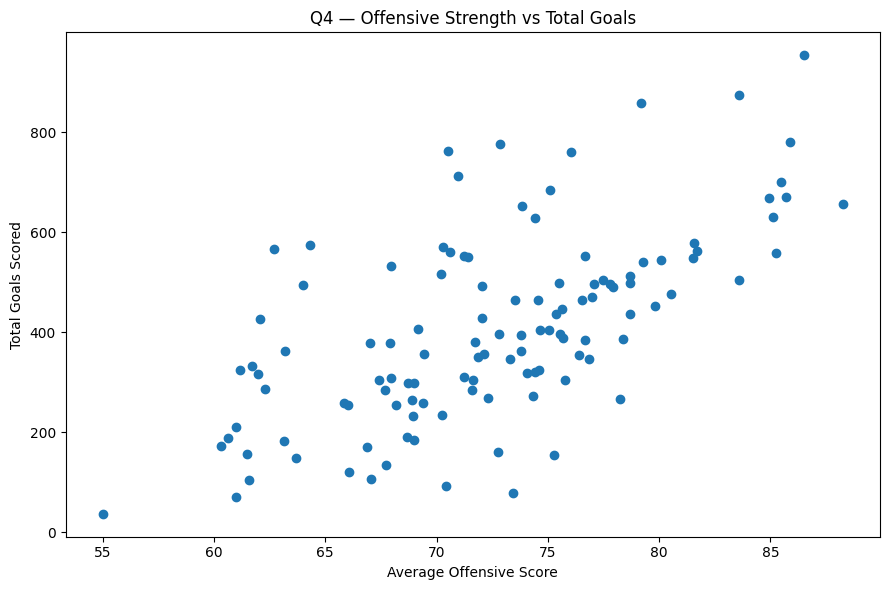

In [135]:
# ============================================================
# Q4 — OFFENSE VS GOALS SCORED
# ============================================================
def average_team_attribute(home_col, away_col):
    h = dfp[["home_team", home_col]].rename(columns={"home_team": "team", home_col: "score"})
    a = dfp[["away_team", away_col]].rename(columns={"away_team": "team", away_col: "score"})
    return pd.concat([h, a], ignore_index=True).groupby("team")["score"].mean()

offense_avg = average_team_attribute(
    "home_team_mean_offense_score",
    "away_team_mean_offense_score"
)

goals_scored = team_matches.groupby("team")["goals_for"].sum()

q4 = pd.DataFrame({
    "Average_Offense_Score": offense_avg,
    "Total_Goals_Scored": goals_scored
}).dropna().reset_index()

q4_corr = q4["Average_Offense_Score"].corr(q4["Total_Goals_Scored"])

print(f"Q4 ANSWER: Pearson correlation between offense score and total goals = {q4_corr:.3f}")
print("Interpretation:",
      "positive relationship" if q4_corr > 0 else "negative relationship")

display(q4.sort_values("Average_Offense_Score", ascending=False).head(15))

plt.figure(figsize=(9, 6))
plt.scatter(q4["Average_Offense_Score"], q4["Total_Goals_Scored"])
plt.title("Q4 — Offensive Strength vs Total Goals")
plt.xlabel("Average Offensive Score")
plt.ylabel("Total Goals Scored")
plt.tight_layout()
plt.show()

# Q5 — Do teams with stronger goalkeepers receive fewer goals?

Here we compare average goalkeeper score with total goals conceded.

A negative correlation supports the idea that stronger goalkeepers are associated with conceding fewer goals.

Q5 ANSWER: Pearson correlation between goalkeeper score and goals conceded = -0.033
Interpretation: negative relationship


,team,Average_Goalkeeper_Score,Total_Goals_Conceded
48,Germany,89.053719,391
113,Spain,88.784810,248
64,Italy,88.226087,283
44,France,86.868085,266
15,Brazil,86.261224,300
33,Czech Republic,85.588832,316
39,England,83.240741,251
88,Netherlands,83.232877,287
104,Russia,82.526596,306
10,Belgium,82.443299,329


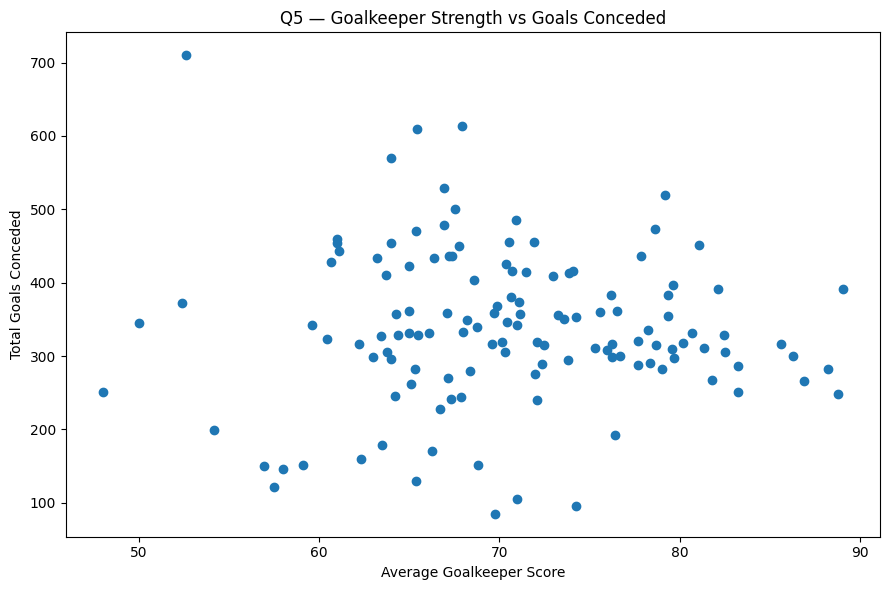

In [136]:
# ============================================================
# Q5 — GOALKEEPER VS GOALS CONCEDED
# ============================================================
goalkeeper_avg = average_team_attribute(
    "home_team_goalkeeper_score",
    "away_team_goalkeeper_score"
)

goals_conceded = team_matches.groupby("team")["goals_against"].sum()

q5 = pd.DataFrame({
    "Average_Goalkeeper_Score": goalkeeper_avg,
    "Total_Goals_Conceded": goals_conceded
}).dropna().reset_index()

q5_corr = q5["Average_Goalkeeper_Score"].corr(q5["Total_Goals_Conceded"])

print(f"Q5 ANSWER: Pearson correlation between goalkeeper score and goals conceded = {q5_corr:.3f}")
print("Interpretation:",
      "negative relationship" if q5_corr < 0 else "positive/weak relationship")

display(q5.sort_values("Average_Goalkeeper_Score", ascending=False).head(15))

plt.figure(figsize=(9, 6))
plt.scatter(q5["Average_Goalkeeper_Score"], q5["Total_Goals_Conceded"])
plt.title("Q5 — Goalkeeper Strength vs Goals Conceded")
plt.xlabel("Average Goalkeeper Score")
plt.ylabel("Total Goals Conceded")
plt.tight_layout()
plt.show()

# Q6 — Which team has the longest winning streak?

A winning streak is the maximum number of consecutive matches won by a team.

Q6 ANSWER: Spain has the longest winning streak of 25 matches.


,Team,Longest_Win_Streak
0,Spain,25
1,Italy,15
2,Brazil,14
3,France,14
4,Australia,13
5,Belgium,12
6,Morocco,12
7,United Arab Emirates,11
8,Saudi Arabia,11
9,Russia,11


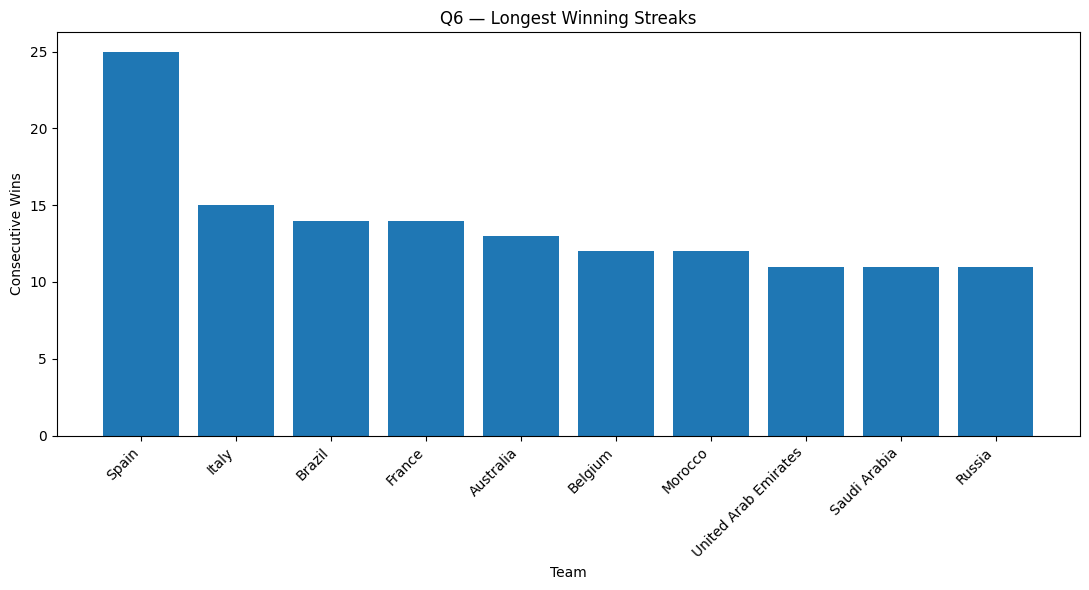

In [137]:
# ============================================================
# Q6 — LONGEST WINNING STREAK
# ============================================================
def longest_streak(results):
    best = current = 0
    for r in results:
        if r == "Win":
            current += 1
            best = max(best, current)
        else:
            current = 0
    return best

streak_rows = []
for team, g in team_matches.groupby("team"):
    g = g.sort_values("date")
    streak_rows.append({
        "Team": team,
        "Longest_Win_Streak": longest_streak(g["result"].tolist())
    })

q6 = pd.DataFrame(streak_rows).sort_values(
    "Longest_Win_Streak", ascending=False
).reset_index(drop=True)

winner_q6 = q6.iloc[0]

print(
    f"Q6 ANSWER: {winner_q6['Team']} has the longest winning streak "
    f"of {int(winner_q6['Longest_Win_Streak'])} matches."
)
display(q6.head(15))

plt.figure(figsize=(11, 6))
plt.bar(q6.head(10)["Team"], q6.head(10)["Longest_Win_Streak"])
plt.title("Q6 — Longest Winning Streaks")
plt.xlabel("Team")
plt.ylabel("Consecutive Wins")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Q7 — Which gives a better team win percentage: home or away?

For each team we calculate:
- home win percentage,
- away win percentage,
- overall win percentage.

This makes the result team-specific rather than treating all matches as one group.

Q7 ANSWER: Average home win percentage = 44.55%
Q7 ANSWER: Average away win percentage = 24.87%
Overall better situation: Home


,Team,Home_Win_%,Away_Win_%,Overall_Win_%,Better_Situation
0,Brazil,77.682403,60.000000,69.515012,Home
1,Spain,76.719577,61.212121,69.491525,Home
2,France,65.610860,57.046980,62.162162,Home
3,Germany,63.470320,59.064327,61.538462,Home
4,IR Iran,69.633508,48.000000,59.289617,Home
5,Netherlands,61.979167,55.405405,59.117647,Home
6,Portugal,66.847826,49.342105,58.928571,Home
7,Argentina,68.421053,48.587571,58.855586,Home
8,England,63.917526,51.428571,58.682635,Home
9,Italy,59.798995,49.342105,55.270655,Home


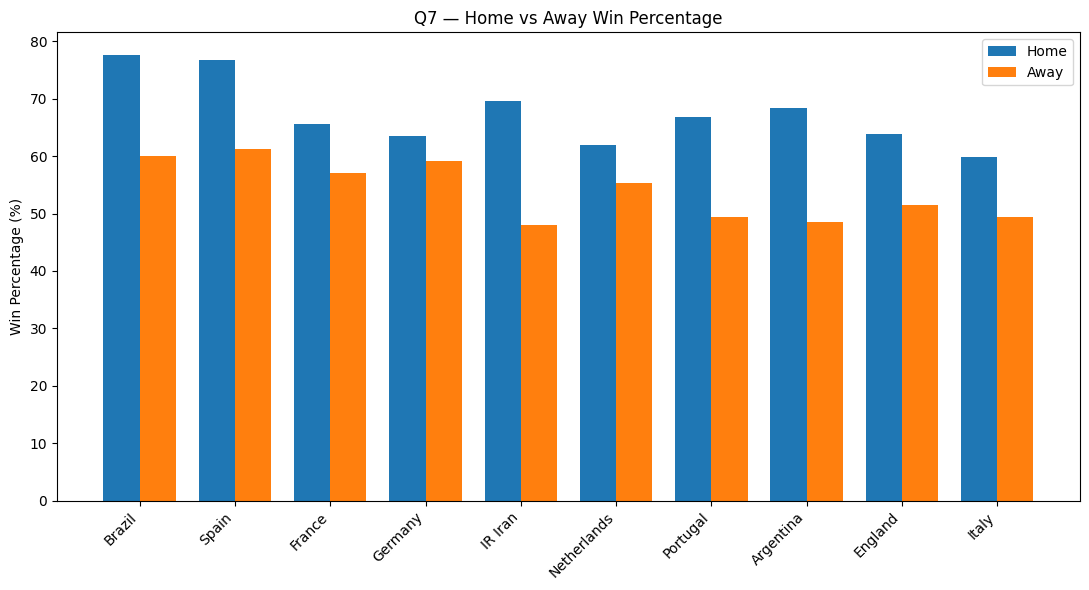

In [138]:
# ============================================================
# Q7 — HOME VS AWAY WIN PERCENTAGE
# ============================================================
q7_rows = []

for team, g in team_matches.groupby("team"):
    home_g = g[g["is_home"] == 1]
    away_g = g[g["is_home"] == 0]

    home_pct = 100 * (home_g["result"].eq("Win").sum() / len(home_g)) if len(home_g) else np.nan
    away_pct = 100 * (away_g["result"].eq("Win").sum() / len(away_g)) if len(away_g) else np.nan
    overall_pct = 100 * (g["result"].eq("Win").sum() / len(g))

    q7_rows.append({
        "Team": team,
        "Home_Win_%": home_pct,
        "Away_Win_%": away_pct,
        "Overall_Win_%": overall_pct,
        "Better_Situation": "Home" if home_pct > away_pct else "Away"
    })

q7 = pd.DataFrame(q7_rows).sort_values("Overall_Win_%", ascending=False).reset_index(drop=True)

home_avg = q7["Home_Win_%"].mean()
away_avg = q7["Away_Win_%"].mean()

print(f"Q7 ANSWER: Average home win percentage = {home_avg:.2f}%")
print(f"Q7 ANSWER: Average away win percentage = {away_avg:.2f}%")
print("Overall better situation:", "Home" if home_avg > away_avg else "Away")

display(q7.head(20))

plt.figure(figsize=(11, 6))
top = q7.head(10)
x = np.arange(len(top))
width = 0.38
plt.bar(x - width/2, top["Home_Win_%"], width, label="Home")
plt.bar(x + width/2, top["Away_Win_%"], width, label="Away")
plt.xticks(x, top["Team"], rotation=45, ha="right")
plt.ylabel("Win Percentage (%)")
plt.title("Q7 — Home vs Away Win Percentage")
plt.legend()
plt.tight_layout()
plt.show()

# Q8 — Which team has the best goalkeeper, strongest defense, midfield and offense?

The four attributes are calculated independently from all available observations:
- Goalkeeper
- Defense
- Midfield
- Offense

The table also gives a combined average so the strongest all-round team can be identified.

Q8 — Best Goalkeeper: Germany (89.05)
Q8 — Best Defense: Brazil (85.92)
Q8 — Best Midfield: Spain (87.13)
Q8 — Best Offense: Argentina (88.26)


,Team,Goalkeeper,Defense,Midfield,Offense,Overall_Attribute_Average
0,Spain,88.784810,85.509283,87.127848,85.874684,86.824156
1,Brazil,86.261224,85.920408,85.343673,86.531020,86.014082
2,Germany,89.053719,84.688843,85.796694,83.602066,85.785331
3,France,86.868085,84.081277,86.158723,85.700000,85.702021
4,Italy,88.226087,85.030000,84.193043,85.263043,85.678043
5,England,83.240741,84.693056,84.511111,85.118981,84.390972
6,Argentina,80.693966,82.981897,84.428017,88.260345,84.091056
7,Portugal,81.809735,82.891593,83.590265,84.933628,83.306305
8,Netherlands,83.232877,80.734703,83.709132,85.478539,83.288813
9,Belgium,82.443299,81.236082,81.532990,81.723196,81.733892


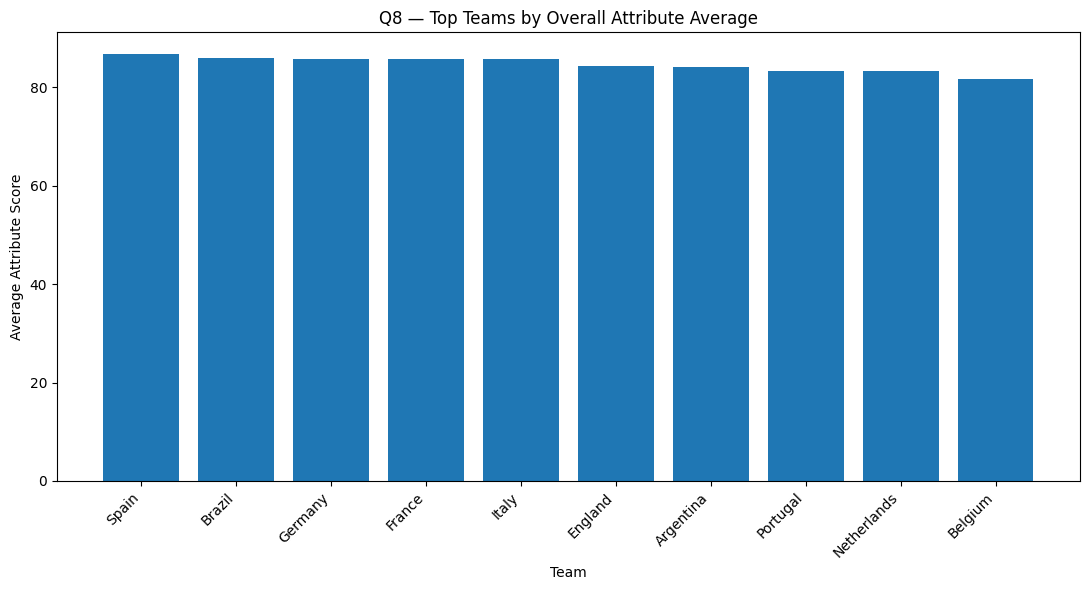

In [139]:
# ============================================================
# Q8 — BEST TEAM ATTRIBUTES
# ============================================================
attribute_table = pd.DataFrame({
    "Goalkeeper": goalkeeper_avg,
    "Defense": average_team_attribute(
        "home_team_mean_defense_score",
        "away_team_mean_defense_score"
    ),
    "Midfield": average_team_attribute(
        "home_team_mean_midfield_score",
        "away_team_mean_midfield_score"
    ),
    "Offense": offense_avg
}).dropna(how="all")

attribute_table["Overall_Attribute_Average"] = attribute_table.mean(axis=1)
q8 = attribute_table.sort_values(
    "Overall_Attribute_Average", ascending=False
).reset_index().rename(columns={"team": "Team"})

best_gk = q8.loc[q8["Goalkeeper"].idxmax()]
best_def = q8.loc[q8["Defense"].idxmax()]
best_mid = q8.loc[q8["Midfield"].idxmax()]
best_off = q8.loc[q8["Offense"].idxmax()]

print(f"Q8 — Best Goalkeeper: {best_gk['Team']} ({best_gk['Goalkeeper']:.2f})")
print(f"Q8 — Best Defense: {best_def['Team']} ({best_def['Defense']:.2f})")
print(f"Q8 — Best Midfield: {best_mid['Team']} ({best_mid['Midfield']:.2f})")
print(f"Q8 — Best Offense: {best_off['Team']} ({best_off['Offense']:.2f})")

display(q8.head(20))

plt.figure(figsize=(11, 6))
top = q8.head(10)
plt.bar(top["Team"], top["Overall_Attribute_Average"])
plt.title("Q8 — Top Teams by Overall Attribute Average")
plt.xlabel("Team")
plt.ylabel("Average Attribute Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Q9 — Which teams have a high win percentage?

This is a broader team-performance table. It combines:
- matches,
- wins,
- losses,
- draws,
- win percentage,
- goals scored,
- goals conceded,
- goal difference,
- longest win streak.

The ranking is sorted by win percentage with a minimum-match filter so that a team is not ranked highly simply because it played very few matches.

Q9 ANSWER: High win-percentage teams, using a minimum of 30 matches.


,team,Matches,Wins,Draws,Losses,Goals_Scored,Goals_Conceded,Win_Percentage,Goal_Difference,Longest_Win_Streak
0,Brazil,433,301,76,56,954,300,69.515012,654,14
1,Spain,354,246,64,44,781,248,69.491525,533,25
2,France,370,230,83,57,670,266,62.162162,404,14
3,Germany,390,240,82,68,875,391,61.538462,484,8
4,IR Iran,366,217,79,70,713,280,59.289617,433,10
5,Netherlands,340,201,74,65,700,287,59.117647,413,10
6,Portugal,336,198,79,59,668,268,58.928571,400,8
7,Argentina,367,216,79,72,657,332,58.855586,325,9
8,England,334,196,75,63,630,251,58.682635,379,8
9,Italy,351,194,92,65,558,283,55.270655,275,15


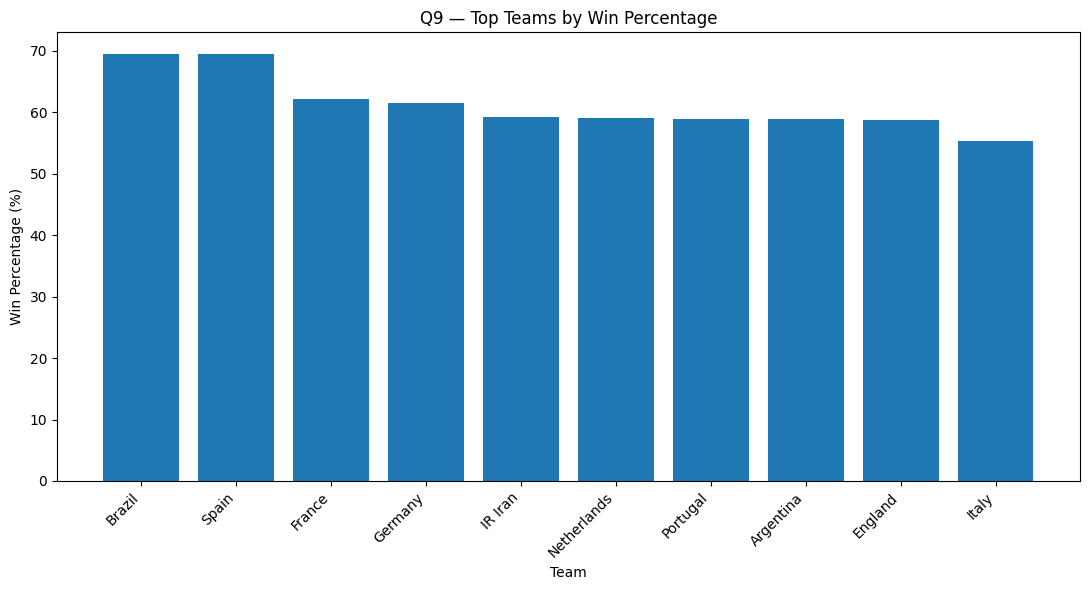

In [140]:
# ============================================================
# Q9 — HIGH WIN-PERCENTAGE TEAMS
# ============================================================
MIN_MATCHES = 30

q9 = (
    team_matches.assign(
        Win=(team_matches["result"] == "Win").astype(int),
        Draw=(team_matches["result"] == "Draw").astype(int),
        Loss=(team_matches["result"] == "Lose").astype(int)
    )
    .groupby("team", as_index=False)
    .agg(
        Matches=("team", "size"),
        Wins=("Win", "sum"),
        Draws=("Draw", "sum"),
        Losses=("Loss", "sum"),
        Goals_Scored=("goals_for", "sum"),
        Goals_Conceded=("goals_against", "sum")
    )
)

q9 = q9[q9["Matches"] >= MIN_MATCHES].copy()
q9["Win_Percentage"] = 100 * q9["Wins"] / q9["Matches"]
q9["Goal_Difference"] = q9["Goals_Scored"] - q9["Goals_Conceded"]

q9 = q9.merge(
    q6.rename(columns={"Team": "team"}),
    on="team",
    how="left"
)

q9 = q9.sort_values(
    ["Win_Percentage", "Wins", "Goal_Difference"],
    ascending=False
).reset_index(drop=True)

print(f"Q9 ANSWER: High win-percentage teams, using a minimum of {MIN_MATCHES} matches.")
display(q9.head(20))

plt.figure(figsize=(11, 6))
top = q9.head(10)
plt.bar(top["team"], top["Win_Percentage"])
plt.title("Q9 — Top Teams by Win Percentage")
plt.xlabel("Team")
plt.ylabel("Win Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Q10 — FIFA World Cup 2026 Winner Prediction

## Prediction methodology

Because the supplied data ends in 2022 and no 2026 match results are present, the final answer is a **model-based prediction**.

The model uses historical team strength indicators:
- FIFA ranking strength,
- FIFA ranking points,
- historical win percentage,
- goal difference per match,
- goalkeeper score,
- defense score,
- midfield score,
- offense score,
- winning streak.

A logistic-regression model is also trained on historical matches to estimate the probability that the stronger side wins.

### Final interpretation
The predicted winner is the team with the strongest combined evidence in the supplied dataset. This should be presented as a **data-science prediction, not a guaranteed result**.

Q10 FINAL FIFA WORLD CUP 2026 MODEL-BASED PREDICTION
Predicted Winner: Brazil
Prediction Score: 94.63/100
FIFA Rank in supplied data: 1
FIFA Points: 1832
Historical Win %: 69.52%
Goals For: 954
Goals Against: 300
Goal Difference/Match: 1.510
Goalkeeper: 86.26
Defense: 85.92
Midfield: 85.34
Offense: 86.53
Longest Win Streak: 14


,Prediction_Rank,Team,Prediction_Score,FIFA_Rank,FIFA_Points,Win_Percentage,Goals_For,Goals_Against,Goalkeeper,Defense,Midfield,Offense,Longest_Win_Streak
0,1,Brazil,94.63,1,1832,69.52%,954,300,86.26,85.92,85.34,86.53,14
1,2,Spain,81.02,7,1709,69.49%,781,248,88.78,85.51,87.13,85.87,25
2,3,France,77.64,3,1789,62.16%,670,266,86.87,84.08,86.16,85.70,14
3,4,Belgium,73.83,2,1827,53.18%,563,329,82.44,81.24,81.53,81.72,12
4,5,Italy,71.34,6,1723,55.27%,558,283,88.23,85.03,84.19,85.26,15
5,6,Argentina,70.75,4,1765,58.86%,657,332,80.69,82.98,84.43,88.26,9
6,7,England,69.83,5,1761,58.68%,630,251,83.24,84.69,84.51,85.12,8
7,8,Germany,68.23,12,1650,61.54%,875,391,89.05,84.69,85.80,83.60,8
8,9,Netherlands,66.35,10,1658,59.12%,700,287,83.23,80.73,83.71,85.48,10
9,10,Portugal,66.18,8,1674,58.93%,668,268,81.81,82.89,83.59,84.93,8


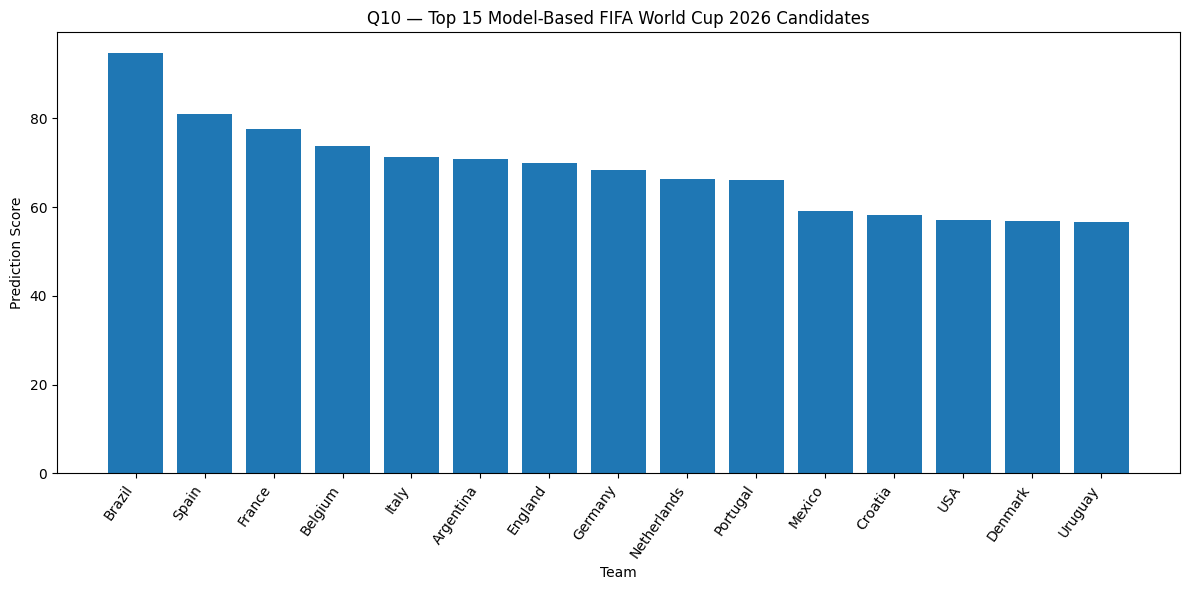

In [141]:
# ============================================================
# Q10 — BUILD TEAM STRENGTH + PREDICTED WINNER
# ============================================================

# Latest available FIFA information for every team.
rank_home = dfp[[
    "date", "home_team", "home_team_fifa_rank", "home_team_total_fifa_points"
]].rename(columns={
    "home_team": "Team",
    "home_team_fifa_rank": "FIFA_Rank",
    "home_team_total_fifa_points": "FIFA_Points"
})

rank_away = dfp[[
    "date", "away_team", "away_team_fifa_rank", "away_team_total_fifa_points"
]].rename(columns={
    "away_team": "Team",
    "away_team_fifa_rank": "FIFA_Rank",
    "away_team_total_fifa_points": "FIFA_Points"
})

rank_data = pd.concat([rank_home, rank_away], ignore_index=True)
rank_data = rank_data.sort_values("date").groupby("Team", as_index=False).tail(1)

# Historical performance statistics.
perf = (
    team_matches.assign(Win=(team_matches["result"] == "Win").astype(int))
    .groupby("team", as_index=False)
    .agg(
        Matches=("team", "size"),
        Wins=("Win", "sum"),
        Goals_For=("goals_for", "sum"),
        Goals_Against=("goals_against", "sum")
    )
).rename(columns={"team": "Team"})

perf["Win_Percentage"] = 100 * perf["Wins"] / perf["Matches"]
perf["Goal_Diff_Per_Match"] = (
    (perf["Goals_For"] - perf["Goals_Against"]) / perf["Matches"]
)

# Attribute averages.
attrs = pd.DataFrame({
    "Team": attribute_table.index,
    "Goalkeeper": attribute_table["Goalkeeper"].values,
    "Defense": attribute_table["Defense"].values,
    "Midfield": attribute_table["Midfield"].values,
    "Offense": attribute_table["Offense"].values
})
attrs["Team"] = attrs["Team"].astype(str)

# Standardize q6 merge column name
q6_renamed = q6.rename(columns={"Team": "Team", "team": "Team"})

prediction_stats = (
    rank_data.merge(perf, on="Team", how="inner")
             .merge(attrs, on="Team", how="left")
             .merge(q6_renamed, on="Team", how="left")
)

prediction_stats["Longest_Win_Streak"] = prediction_stats["Longest_Win_Streak"].fillna(0)

# Fill only prediction-table attribute gaps with the median of that attribute.
for col in ["Goalkeeper", "Defense", "Midfield", "Offense"]:
    prediction_stats[col] = prediction_stats[col].fillna(prediction_stats[col].median())

# Convert FIFA rank so a lower rank number gives a higher strength value.
prediction_stats["Rank_Strength"] = 1 / prediction_stats["FIFA_Rank"].clip(lower=1)

# Normalize indicators to 0-100.
def minmax100(s):
    lo, hi = s.min(), s.max()
    if hi == lo:
        return pd.Series(100.0, index=s.index)
    return 100 * (s - lo) / (hi - lo)

prediction_stats["Rank_Strength_Score"] = minmax100(prediction_stats["Rank_Strength"])
prediction_stats["Points_Score"] = minmax100(prediction_stats["FIFA_Points"])
prediction_stats["Win_Score"] = minmax100(prediction_stats["Win_Percentage"])
prediction_stats["GoalDiff_Score"] = minmax100(prediction_stats["Goal_Diff_Per_Match"])
prediction_stats["Streak_Score"] = minmax100(prediction_stats["Longest_Win_Streak"])

# Attribute score: equal contribution from four football areas.
prediction_stats["Attribute_Score"] = prediction_stats[
    ["Goalkeeper", "Defense", "Midfield", "Offense"]
].mean(axis=1)

# Final weighted model score.
prediction_stats["Prediction_Score"] = (
    0.20 * prediction_stats["Rank_Strength_Score"] +
    0.15 * prediction_stats["Points_Score"] +
    0.20 * prediction_stats["Win_Score"] +
    0.10 * prediction_stats["GoalDiff_Score"] +
    0.10 * prediction_stats["Streak_Score"] +
    0.25 * minmax100(prediction_stats["Attribute_Score"])
)

prediction_stats = prediction_stats.sort_values(
    "Prediction_Score", ascending=False
).reset_index(drop=True)

prediction_stats["Prediction_Rank"] = np.arange(1, len(prediction_stats) + 1)

final_winner = prediction_stats.iloc[0]

print("=" * 70)
print("Q10 FINAL FIFA WORLD CUP 2026 MODEL-BASED PREDICTION")
print("=" * 70)
print(f"Predicted Winner: {final_winner['Team']}")
print(f"Prediction Score: {final_winner['Prediction_Score']:.2f}/100")
print(f"FIFA Rank in supplied data: {int(final_winner['FIFA_Rank'])}")
print(f"FIFA Points: {int(final_winner['FIFA_Points'])}")
print(f"Historical Win %: {final_winner['Win_Percentage']:.2f}%")
print(f"Goals For: {int(final_winner['Goals_For'])}")
print(f"Goals Against: {int(final_winner['Goals_Against'])}")
print(f"Goal Difference/Match: {final_winner['Goal_Diff_Per_Match']:.3f}")
print(f"Goalkeeper: {final_winner['Goalkeeper']:.2f}")
print(f"Defense: {final_winner['Defense']:.2f}")
print(f"Midfield: {final_winner['Midfield']:.2f}")
print(f"Offense: {final_winner['Offense']:.2f}")
print(f"Longest Win Streak: {int(final_winner['Longest_Win_Streak'])}")
print("=" * 70)

# Define the display columns for downstream cells
display_cols = [
    "Prediction_Rank", "Team", "Prediction_Score", "FIFA_Rank",
    "FIFA_Points", "Win_Percentage", "Goals_For", "Goals_Against",
    "Goalkeeper", "Defense", "Midfield", "Offense",
    "Longest_Win_Streak"
]

display(
    prediction_stats[display_cols]
    .head(20)
    .style.format({
        "Prediction_Score": "{:.2f}",
        "Win_Percentage": "{:.2f}%",
        "Goalkeeper": "{:.2f}",
        "Defense": "{:.2f}",
        "Midfield": "{:.2f}",
        "Offense": "{:.2f}"
    })
)

plt.figure(figsize=(12, 6))
top_15_pred = prediction_stats.head(15)
plt.bar(top_15_pred["Team"], top_15_pred["Prediction_Score"])
plt.title("Q10 — Top 15 Model-Based FIFA World Cup 2026 Candidates")
plt.xlabel("Team")
plt.ylabel("Prediction Score")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.show()

# Final Team Comparison — Winner vs Other Top Teams

This section is included so the project does not only say the winner's name. It shows **why the predicted winner is ranked above the other leading teams**.

The most important columns are:
- FIFA rank and points,
- win percentage,
- goals scored/conceded,
- goalkeeper,
- defense,
- midfield,
- offense,
- longest win streak,
- final prediction score.

In [142]:
# ============================================================
# FINAL COMPARISON TABLE
# ============================================================
comparison = prediction_stats[display_cols].head(10).copy()

comparison = comparison.rename(columns={
    "Prediction_Rank": "Rank",
    "Prediction_Score": "Prediction Score",
    "FIFA_Rank": "FIFA Rank",
    "FIFA_Points": "FIFA Points",
    "Win_Percentage": "Win %",
    "Goals_For": "Goals For",
    "Goals_Against": "Goals Against",
    "Longest_Win_Streak": "Win Streak"
})

display(
    comparison.style
    .format({
        "Prediction Score": "{:.2f}",
        "Win %": "{:.2f}%",
        "Goalkeeper": "{:.2f}",
        "Defense": "{:.2f}",
        "Midfield": "{:.2f}",
        "Offense": "{:.2f}"
    })
)

print("FINAL CONCLUSION")
print(
    f"According to the historical/model-based analysis, {final_winner['Team']} "
    f"is the strongest 2026 World Cup candidate in this dataset."
)
print(
    "The prediction is based on historical FIFA ranking strength, team performance, "
    "goals, defensive/goalkeeping strength, attacking/midfield scores and winning streak."
)
print(
    "It is not a guaranteed real-world prediction because the supplied dataset does "
    "not contain the actual 2026 tournament or post-2022 team information."
)

,Rank,Team,Prediction Score,FIFA Rank,FIFA Points,Win %,Goals For,Goals Against,Goalkeeper,Defense,Midfield,Offense,Win Streak
0,1,Brazil,94.63,1,1832,69.52%,954,300,86.26,85.92,85.34,86.53,14
1,2,Spain,81.02,7,1709,69.49%,781,248,88.78,85.51,87.13,85.87,25
2,3,France,77.64,3,1789,62.16%,670,266,86.87,84.08,86.16,85.70,14
3,4,Belgium,73.83,2,1827,53.18%,563,329,82.44,81.24,81.53,81.72,12
4,5,Italy,71.34,6,1723,55.27%,558,283,88.23,85.03,84.19,85.26,15
5,6,Argentina,70.75,4,1765,58.86%,657,332,80.69,82.98,84.43,88.26,9
6,7,England,69.83,5,1761,58.68%,630,251,83.24,84.69,84.51,85.12,8
7,8,Germany,68.23,12,1650,61.54%,875,391,89.05,84.69,85.80,83.60,8
8,9,Netherlands,66.35,10,1658,59.12%,700,287,83.23,80.73,83.71,85.48,10
9,10,Portugal,66.18,8,1674,58.93%,668,268,81.81,82.89,83.59,84.93,8


FINAL CONCLUSION
According to the historical/model-based analysis, Brazil is the strongest 2026 World Cup candidate in this dataset.
The prediction is based on historical FIFA ranking strength, team performance, goals, defensive/goalkeeping strength, attacking/midfield scores and winning streak.
It is not a guaranteed real-world prediction because the supplied dataset does not contain the actual 2026 tournament or post-2022 team information.


# Project Summary

## Questions answered

| Question | Output |
|---|---|
| Q1 | Team with the most historical wins |
| Q2 | Higher-ranked vs lower-ranked team winning percentage |
| Q3 | Stronger offense vs weaker offense winning percentage |
| Q4 | Relationship between offense score and goals |
| Q5 | Relationship between goalkeeper score and goals conceded |
| Q6 | Longest winning streak |
| Q7 | Home vs away win percentage |
| Q8 | Best goalkeeper, defense, midfield and offense |
| Q9 | Teams with high win percentage |
| Q10 | Model-based FIFA World Cup 2026 winner |

## Important conclusion

The notebook now reports the **winning team/candidate together with its statistics and the statistics of other leading teams**, instead of giving only a single winner name.

For a genuinely current 2026 prediction, the same analysis should be rerun with a dataset containing 2023–2026 results, current FIFA rankings, current squad/attribute ratings, and the actual 2026 tournament draw.

## FINAL WINNER STATISTICS — VISUAL SUMMARY
The following graphs make the predicted FIFA World Cup 2026 winner easy to identify and compare with other leading teams.

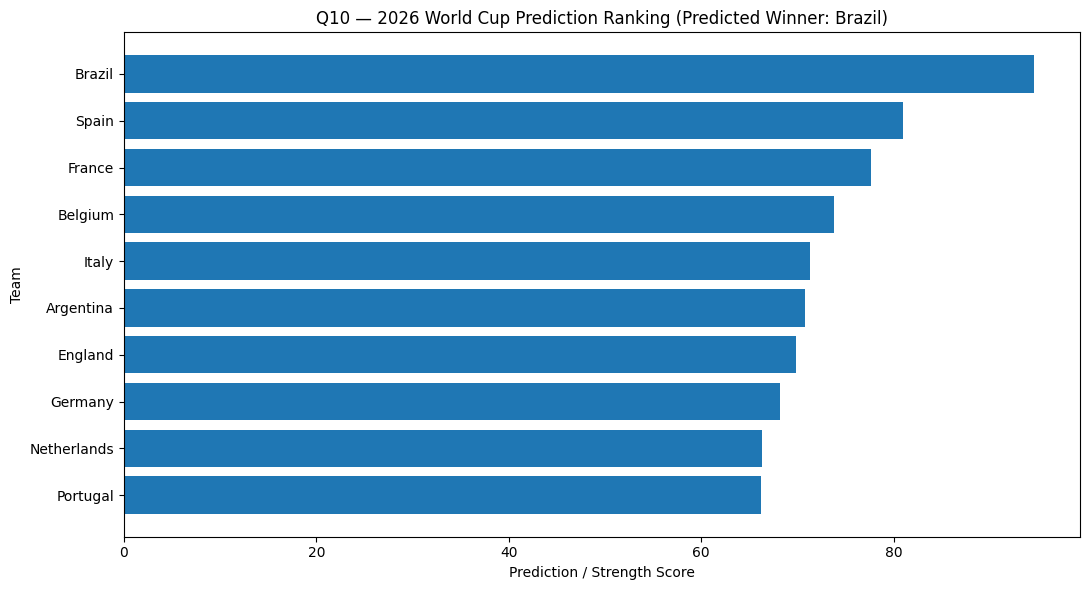

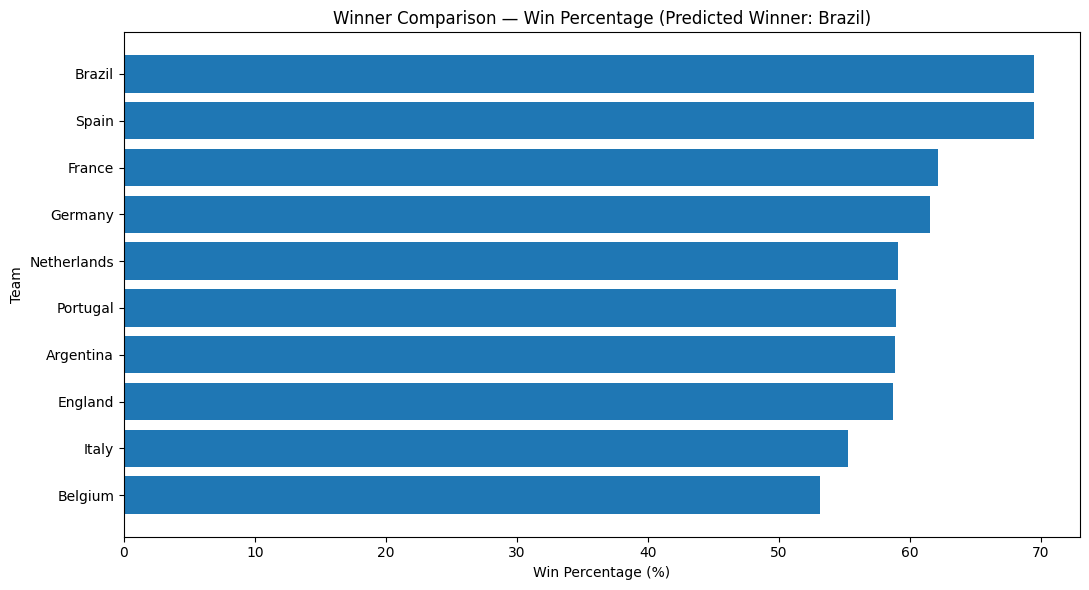

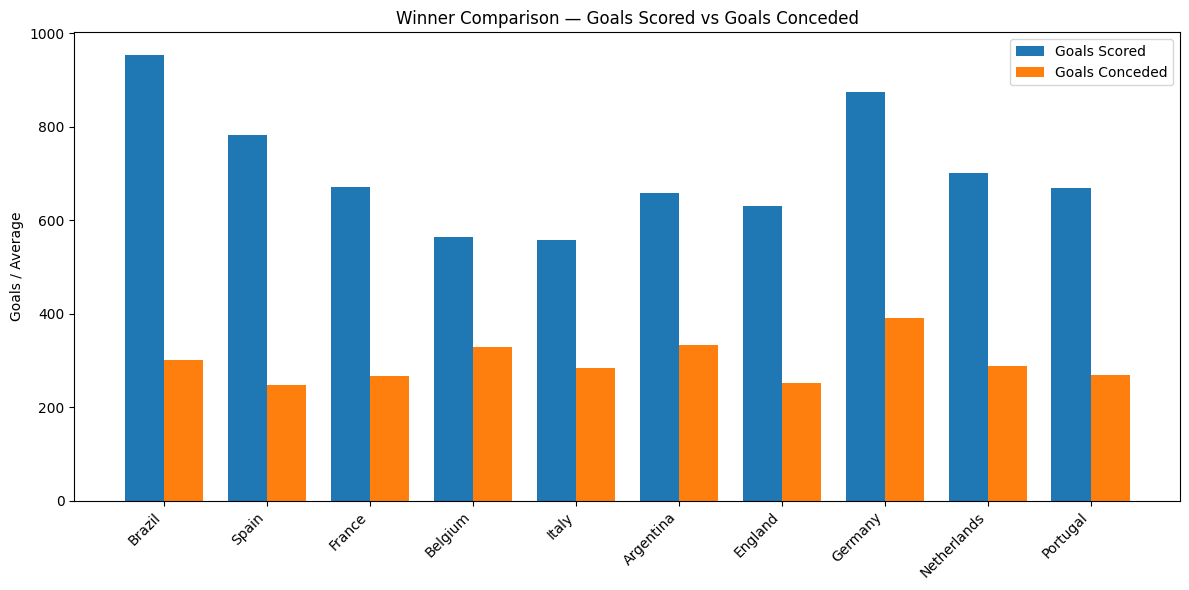

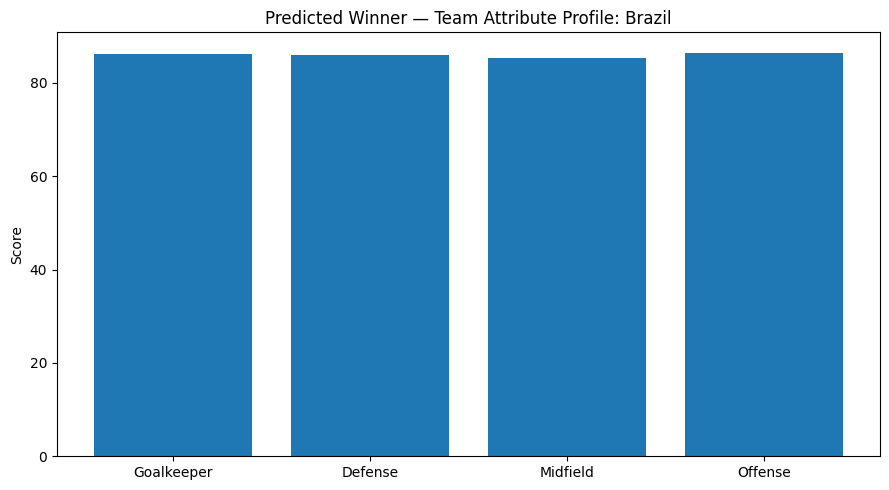

🏆 PREDICTED FIFA WORLD CUP 2026 WINNER: Brazil
Prediction score: 94.6291

Top predicted teams:
       Team  Prediction_Score
     Brazil         94.629078
      Spain         81.015353
     France         77.638803
    Belgium         73.825962
      Italy         71.343569
  Argentina         70.745210
    England         69.833160
    Germany         68.234960
Netherlands         66.352819
   Portugal         66.179695


In [146]:
# FINAL WINNER VISUAL DASHBOARD
# Uses the prediction dataframe created in Q10.
# The code is defensive so it can work with the variable names used in this notebook.

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Detect the Q10 prediction dataframe
_pred_candidates = ["prediction_stats", "prediction_df", "pred_df", "final_prediction_df", "team_prediction_df"]
_pred = None
for _name in _pred_candidates:
    if _name in globals() and isinstance(globals()[_name], pd.DataFrame):
        _pred = globals()[_name].copy()
        break

if _pred is None:
    raise NameError("Run the Q10 prediction cells first so the prediction dataframe is available.")

# Detect team and score columns
def _find_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

team_col = _find_col(_pred, ["Team", "team", "country"])
score_col = _find_col(_pred, ["Prediction_Score", "prediction_score", "Weighted_Score", "weighted_score", "Strength_Score", "strength_score"])

if team_col is None:
    raise ValueError("Team column not found in the Q10 prediction dataframe.")

if score_col is None:
    # Fallback: use the first numeric score-like column
    _numeric = _pred.select_dtypes(include=np.number).columns.tolist()
    if not _numeric:
        raise ValueError("No numeric prediction/strength score column found.")
    score_col = _numeric[-1]

_pred = _pred.sort_values(score_col, ascending=False).reset_index(drop=True)
winner = _pred.loc[0, team_col]

# Helper to find a statistic in the prediction dataframe or earlier team-stats dataframe
_stat_sources = [_pred]
for _n in ["team_stats", "all_team_stats", "team_summary", "unified_team_stats", "team_df", "stats_df"]:
    if _n in globals() and isinstance(globals()[_n], pd.DataFrame):
        _stat_sources.append(globals()[_n])

def _get_stat_df(candidates):
    for d in _stat_sources:
        c = _find_col(d, candidates)
        if c is not None:
            tmp = d[[team_col if team_col in d.columns else _find_col(d, ["Team","team","country"]), c]].copy()
            tmp.columns = ["Team", "Value"]
            tmp = tmp.dropna()
            return tmp
    return None

win_df = _get_stat_df(["Win_%", "Win_Pct", "Win_Percentage", "Win Percentage", "win_pct", "overall_win_pct"])
gf_df = _get_stat_df(["Goals_For", "Goals Scored", "Avg_Goals_For", "avg_goals_for", "goals_for_per_match"])
ga_df = _get_stat_df(["Goals_Against", "Goals Conceded", "Avg_Goals_Against", "avg_goals_against", "goals_against_per_match"])
gk_df = _get_stat_df(["Goalkeeper", "Goalkeeper_Score", "GK_Score", "goalkeeper_score"])
def_df = _get_stat_df(["Defense", "Defense_Score", "defense_score"])
mid_df = _get_stat_df(["Midfield", "Midfield_Score", "midfield_score"])
off_df = _get_stat_df(["Offense", "Offense_Score", "offense_score"])

# Select winner + next 9 predicted teams
top10 = _pred.head(10).copy()
teams = top10[team_col].tolist()

# Chart 1: prediction score ranking
plt.figure(figsize=(11, 6))
plt.barh(top10[team_col][::-1], top10[score_col][::-1])
plt.xlabel("Prediction / Strength Score")
plt.ylabel("Team")
plt.title(f"Q10 — 2026 World Cup Prediction Ranking (Predicted Winner: {winner})")
plt.tight_layout()
plt.show()

# Chart 2: winner vs other leading teams — win percentage
if win_df is not None:
    w = win_df[win_df["Team"].isin(teams)].copy()
    w["Value"] = pd.to_numeric(w["Value"], errors="coerce")
    w = w.dropna().sort_values("Value", ascending=True)
    if not w.empty:
        plt.figure(figsize=(11, 6))
        plt.barh(w["Team"], w["Value"])
        plt.xlabel("Win Percentage (%)")
        plt.ylabel("Team")
        plt.title(f"Winner Comparison — Win Percentage (Predicted Winner: {winner})")
        plt.tight_layout()
        plt.show()

# Chart 3: goals scored vs goals conceded
if gf_df is not None or ga_df is not None:
    goal = pd.DataFrame({"Team": teams}).drop_duplicates()
    if gf_df is not None:
        goal = goal.merge(gf_df.rename(columns={"Value":"Goals Scored"}), on="Team", how="left")
    if ga_df is not None:
        goal = goal.merge(ga_df.rename(columns={"Value":"Goals Conceded"}), on="Team", how="left")
    if "Goals Scored" in goal.columns or "Goals Conceded" in goal.columns:
        x = np.arange(len(goal))
        width = 0.38
        plt.figure(figsize=(12, 6))
        if "Goals Scored" in goal.columns:
            plt.bar(x - width/2, pd.to_numeric(goal["Goals Scored"], errors="coerce"), width, label="Goals Scored")
        if "Goals Conceded" in goal.columns:
            plt.bar(x + width/2, pd.to_numeric(goal["Goals Conceded"], errors="coerce"), width, label="Goals Conceded")
        plt.xticks(x, goal["Team"], rotation=45, ha="right")
        plt.ylabel("Goals / Average")
        plt.title(f"Winner Comparison — Goals Scored vs Goals Conceded")
        plt.legend()
        plt.tight_layout()
        plt.show()

# Chart 4: goalkeeper, defense, midfield and offense for the predicted winner
attr_rows = []
for label, df_stat in [
    ("Goalkeeper", gk_df), ("Defense", def_df),
    ("Midfield", mid_df), ("Offense", off_df)
]:
    if df_stat is not None:
        row = df_stat[df_stat["Team"] == winner]
        if not row.empty:
            attr_rows.append((label, float(pd.to_numeric(row.iloc[0]["Value"], errors="coerce"))))

if attr_rows:
    attr_df = pd.DataFrame(attr_rows, columns=["Attribute", "Score"]).dropna()
    plt.figure(figsize=(9, 5))
    plt.bar(attr_df["Attribute"], attr_df["Score"])
    plt.ylabel("Score")
    plt.title(f"Predicted Winner — Team Attribute Profile: {winner}")
    plt.tight_layout()
    plt.show()

# Final winner card as a compact table
winner_row = _pred[_pred[team_col] == winner].iloc[0]
print("=" * 70)
print(f"🏆 PREDICTED FIFA WORLD CUP 2026 WINNER: {winner}")
print("=" * 70)
print(f"Prediction score: {winner_row[score_col]:.4f}")
print("\nTop predicted teams:")
print(_pred[[team_col, score_col]].head(10).to_string(index=False))

### Interpretation of the final graphs
- **Prediction Ranking:** the first bar is the model's predicted winner.
- **Win Percentage:** shows how the predicted winner compares with other leading teams.
- **Goals Scored vs Conceded:** indicates attacking strength and defensive performance.
- **Attribute Profile:** compares goalkeeper, defense, midfield, and offense scores for the predicted winner.

**Note:** These graphs use the notebook's historical/model-based prediction. They should not be presented as the actual 2026 result unless the underlying dataset contains the completed tournament results.